## Dataset Loading and Exploration

In [1]:
!pip uninstall -y torchao > /dev/null 2>&1 || true
!pip install -q "huggingface_hub==0.28.1" "transformers==4.48.3" "peft==0.14.0" "accelerate==1.3.0" "datasets==3.2.0" scikit-learn pandas matplotlib seaborn tqdm

In [2]:
from tqdm.auto import tqdm

In [3]:
from datasets import load_dataset

# Load BANKING77
ds = load_dataset("PolyAI/banking77")

# Display dataset information
print(ds)

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 10003
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 3080
    })
})


In [4]:
print("Dataset splits:", list(ds.keys()))

print("\nTraining features:")
print(ds["train"].features)

print("\nTesting features:")
print(ds["test"].features)

print("\nTraining examples:", len(ds["train"]))
print("Testing examples:", len(ds["test"]))

print("\nTotal examples:",
      len(ds["train"]) + len(ds["test"]))

Dataset splits: ['train', 'test']

Training features:
{'text': Value(dtype='string', id=None), 'label': ClassLabel(names=['activate_my_card', 'age_limit', 'apple_pay_or_google_pay', 'atm_support', 'automatic_top_up', 'balance_not_updated_after_bank_transfer', 'balance_not_updated_after_cheque_or_cash_deposit', 'beneficiary_not_allowed', 'cancel_transfer', 'card_about_to_expire', 'card_acceptance', 'card_arrival', 'card_delivery_estimate', 'card_linking', 'card_not_working', 'card_payment_fee_charged', 'card_payment_not_recognised', 'card_payment_wrong_exchange_rate', 'card_swallowed', 'cash_withdrawal_charge', 'cash_withdrawal_not_recognised', 'change_pin', 'compromised_card', 'contactless_not_working', 'country_support', 'declined_card_payment', 'declined_cash_withdrawal', 'declined_transfer', 'direct_debit_payment_not_recognised', 'disposable_card_limits', 'edit_personal_details', 'exchange_charge', 'exchange_rate', 'exchange_via_app', 'extra_charge_on_statement', 'failed_transfer', 

In [5]:
import pandas as pd

train_df = ds["train"].to_pandas()
test_df = ds["test"].to_pandas()

print("First 10 training examples:")

display(train_df.head(10))

First 10 training examples:


,text,label
0,I am still waiting on my card?,11
1,What can I do if my card still hasn't arrived ...,11
2,I have been waiting over a week. Is the card s...,11
3,Can I track my card while it is in the process...,11
4,"How do I know if I will get my card, or if it ...",11
5,When did you send me my new card?,11
6,Do you have info about the card on delivery?,11
7,What do I do if I still have not received my n...,11
8,Does the package with my card have tracking?,11
9,I ordered my card but it still isn't here,11


In [6]:
# inspect individual records
for i in range(5):
    example = ds["train"][i]

    print(f"\nExample {i+1}")
    print("Query:", example["text"])
    print("Label ID:", example["label"])
    print(
        "Intent:",
        ds["train"].features["label"].int2str(
            example["label"]
        )
    )


Example 1
Query: I am still waiting on my card?
Label ID: 11
Intent: card_arrival

Example 2
Query: What can I do if my card still hasn't arrived after 2 weeks?
Label ID: 11
Intent: card_arrival

Example 3
Query: I have been waiting over a week. Is the card still coming?
Label ID: 11
Intent: card_arrival

Example 4
Query: Can I track my card while it is in the process of delivery?
Label ID: 11
Intent: card_arrival

Example 5
Query: How do I know if I will get my card, or if it is lost?
Label ID: 11
Intent: card_arrival


In [7]:
label_feature = ds["train"].features["label"]

class_names = label_feature.names

print("Total number of intent classes:",
      len(class_names))

print("\nAll 77 intent classes:\n")

for i, intent in enumerate(class_names):
    print(f"{i:02d} : {intent}")

Total number of intent classes: 77

All 77 intent classes:

00 : activate_my_card
01 : age_limit
02 : apple_pay_or_google_pay
03 : atm_support
04 : automatic_top_up
05 : balance_not_updated_after_bank_transfer
06 : balance_not_updated_after_cheque_or_cash_deposit
07 : beneficiary_not_allowed
08 : cancel_transfer
09 : card_about_to_expire
10 : card_acceptance
11 : card_arrival
12 : card_delivery_estimate
13 : card_linking
14 : card_not_working
15 : card_payment_fee_charged
16 : card_payment_not_recognised
17 : card_payment_wrong_exchange_rate
18 : card_swallowed
19 : cash_withdrawal_charge
20 : cash_withdrawal_not_recognised
21 : change_pin
22 : compromised_card
23 : contactless_not_working
24 : country_support
25 : declined_card_payment
26 : declined_cash_withdrawal
27 : declined_transfer
28 : direct_debit_payment_not_recognised
29 : disposable_card_limits
30 : edit_personal_details
31 : exchange_charge
32 : exchange_rate
33 : exchange_via_app
34 : extra_charge_on_statement
35 : failed

#### Check class distribution

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns

class_counts = (
    train_df["label"]
    .value_counts()
    .sort_index()
)

distribution_df = pd.DataFrame({
    "label_id": class_counts.index,
    "intent": [
        class_names[i] for i in class_counts.index
    ],
    "count": class_counts.values
})

print(distribution_df.to_string(index=False))

print("\nMinimum examples per class:",
      distribution_df["count"].min())

print("Maximum examples per class:",
      distribution_df["count"].max())

print("Mean examples per class:",
      round(distribution_df["count"].mean(), 2))

 label_id                                           intent  count
        0                                 activate_my_card    159
        1                                        age_limit    110
        2                          apple_pay_or_google_pay    126
        3                                      atm_support     87
        4                                 automatic_top_up    127
        5          balance_not_updated_after_bank_transfer    171
        6 balance_not_updated_after_cheque_or_cash_deposit    181
        7                          beneficiary_not_allowed    156
        8                                  cancel_transfer    157
        9                             card_about_to_expire    129
       10                                  card_acceptance     59
       11                                     card_arrival    153
       12                           card_delivery_estimate    112
       13                                     card_linking    139
       14 

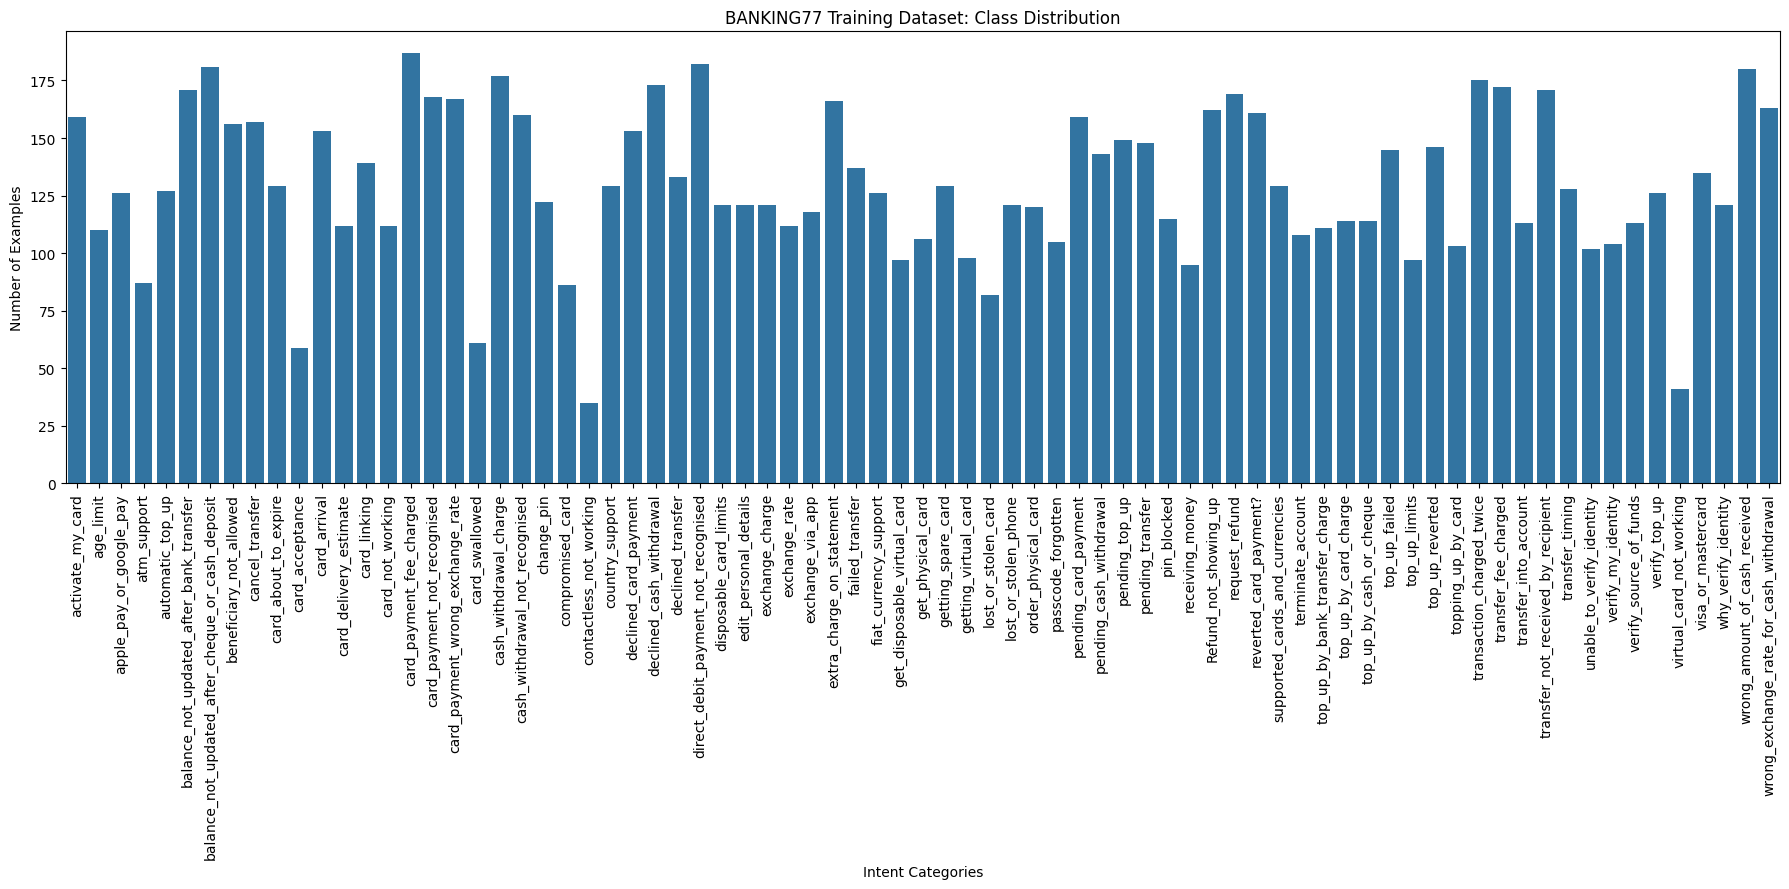

In [9]:
plt.figure(figsize=(18, 9))

sns.barplot(
    data=distribution_df,
    x="intent",
    y="count"
)

plt.xticks(rotation=90)
plt.title("BANKING77 Training Dataset: Class Distribution")
plt.xlabel("Intent Categories")
plt.ylabel("Number of Examples")
plt.tight_layout()

plt.show()

In [10]:
print("Available intent classes:")

for intent in class_names:
    print(intent)

Available intent classes:
activate_my_card
age_limit
apple_pay_or_google_pay
atm_support
automatic_top_up
balance_not_updated_after_bank_transfer
balance_not_updated_after_cheque_or_cash_deposit
beneficiary_not_allowed
cancel_transfer
card_about_to_expire
card_acceptance
card_arrival
card_delivery_estimate
card_linking
card_not_working
card_payment_fee_charged
card_payment_not_recognised
card_payment_wrong_exchange_rate
card_swallowed
cash_withdrawal_charge
cash_withdrawal_not_recognised
change_pin
compromised_card
contactless_not_working
country_support
declined_card_payment
declined_cash_withdrawal
declined_transfer
direct_debit_payment_not_recognised
disposable_card_limits
edit_personal_details
exchange_charge
exchange_rate
exchange_via_app
extra_charge_on_statement
failed_transfer
fiat_currency_support
get_disposable_virtual_card
get_physical_card
getting_spare_card
getting_virtual_card
lost_or_stolen_card
lost_or_stolen_phone
order_physical_card
passcode_forgotten
pending_card_pay

In [11]:
# Select the first 4 available intent categories
selected_intents = class_names[:4]

for intent in selected_intents:

    intent_id = class_names.index(intent)

    examples = train_df[
        train_df["label"] == intent_id
    ].head(3)

    print("\n" + "=" * 70)
    print("INTENT:", intent)
    print("=" * 70)

    for query in examples["text"]:
        print("-", query)


INTENT: activate_my_card
- Please help me with my card.  It won't activate.
- I tired but an unable to activate my card.
- I want to start using my card.

INTENT: age_limit
- I want to open an account for my children
- How old do you need to be to use the banks services?
- Whats the minimum age to have an account

INTENT: apple_pay_or_google_pay
- Hi, I have an apple watch. How do I use it to top up my card?
- Can I use google pay to top up?
- why top up is not working even if I got my American Express in Apple Bay?

INTENT: atm_support
- I can use this card at which ATMs?
- Can I use the card at any cash machine?
- What locations can I get money from?


In [12]:
print("Total classes:", len(class_names))
print("Unique training labels:", train_df["label"].nunique())

print("\nLabel mapping:")

for i, name in enumerate(class_names):
    print(f"{i}: {name}")

Total classes: 77
Unique training labels: 77

Label mapping:
0: activate_my_card
1: age_limit
2: apple_pay_or_google_pay
3: atm_support
4: automatic_top_up
5: balance_not_updated_after_bank_transfer
6: balance_not_updated_after_cheque_or_cash_deposit
7: beneficiary_not_allowed
8: cancel_transfer
9: card_about_to_expire
10: card_acceptance
11: card_arrival
12: card_delivery_estimate
13: card_linking
14: card_not_working
15: card_payment_fee_charged
16: card_payment_not_recognised
17: card_payment_wrong_exchange_rate
18: card_swallowed
19: cash_withdrawal_charge
20: cash_withdrawal_not_recognised
21: change_pin
22: compromised_card
23: contactless_not_working
24: country_support
25: declined_card_payment
26: declined_cash_withdrawal
27: declined_transfer
28: direct_debit_payment_not_recognised
29: disposable_card_limits
30: edit_personal_details
31: exchange_charge
32: exchange_rate
33: exchange_via_app
34: extra_charge_on_statement
35: failed_transfer
36: fiat_currency_support
37: get_d

#### Dataset integrity checks

In [13]:
print("TRAINING SET")
print("Missing values:\n", train_df.isnull().sum())
print("Duplicate queries:", train_df["text"].duplicated().sum())
print("Unique classes:", train_df["label"].nunique())

print("\nTEST SET")
print("Missing values:\n", test_df.isnull().sum())
print("Duplicate queries:", test_df["text"].duplicated().sum())
print("Unique classes:", test_df["label"].nunique())

# Verify label mappings
assert ds["train"].features["label"].names == \
       ds["test"].features["label"].names

assert train_df["label"].nunique() == 77
assert test_df["label"].nunique() == 77

print("\nAll dataset integrity checks passed!")

TRAINING SET
Missing values:
 text     0
label    0
dtype: int64
Duplicate queries: 0
Unique classes: 77

TEST SET
Missing values:
 text     0
label    0
dtype: int64
Duplicate queries: 0
Unique classes: 77

All dataset integrity checks passed!


## Stratified Train/Validation/Test Split

In [14]:
from datasets import DatasetDict
import pandas as pd
import numpy as np

In [15]:
# Reproducibility
SEED = 42

# Split original training data into 90% train and 10% validation
split_data = ds["train"].train_test_split(
    test_size=0.10,
    seed=SEED,
    stratify_by_column="label"
)

# Construct final dataset dictionary
final_ds = DatasetDict({
    "train": split_data["train"],
    "validation": split_data["test"],
    "test": ds["test"]
})

print(final_ds)

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 9002
    })
    validation: Dataset({
        features: ['text', 'label'],
        num_rows: 1001
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 3080
    })
})


In [16]:
print("=" * 50)
print("FINAL DATASET DISTRIBUTION")
print("=" * 50)

for split in final_ds.keys():
    print(f"{split.upper():12s}: {len(final_ds[split]):,} examples")

total = sum(len(final_ds[s]) for s in final_ds)

print("-" * 50)
print(f"{'TOTAL':12s}: {total:,} examples")

FINAL DATASET DISTRIBUTION
TRAIN       : 9,002 examples
VALIDATION  : 1,001 examples
TEST        : 3,080 examples
--------------------------------------------------
TOTAL       : 13,083 examples


In [17]:
NUM_CLASSES = len(class_names)

for split in final_ds.keys():

    labels = final_ds[split]["label"]
    unique_labels = set(labels)

    print(f"\n{split.upper()}")
    print("Total examples:", len(final_ds[split]))
    print("Unique classes:", len(unique_labels))
    print("Missing classes:", NUM_CLASSES - len(unique_labels))

    assert len(unique_labels) == NUM_CLASSES, \
        f"Some classes are missing from {split}"

print("\nAll 77 classes are present in all splits!")


TRAIN
Total examples: 9002
Unique classes: 77
Missing classes: 0

VALIDATION
Total examples: 1001
Unique classes: 77
Missing classes: 0

TEST
Total examples: 3080
Unique classes: 77
Missing classes: 0

All 77 classes are present in all splits!


In [18]:
distribution_comparison = pd.DataFrame({
    split: (
        pd.Series(final_ds[split]["label"])
        .value_counts(normalize=True)
        .reindex(range(NUM_CLASSES), fill_value=0)
        * 100
    )
    for split in final_ds.keys()
})

distribution_comparison.index = class_names

distribution_comparison.index.name = "intent"

display(
    distribution_comparison.round(2).head(15)
)

,train,validation,test
intent,,,
activate_my_card,1.59,1.6,1.3
age_limit,1.10,1.1,1.3
apple_pay_or_google_pay,1.26,1.3,1.3
atm_support,0.87,0.9,1.3
automatic_top_up,1.27,1.3,1.3
balance_not_updated_after_bank_transfer,1.71,1.7,1.3
balance_not_updated_after_cheque_or_cash_deposit,1.81,1.8,1.3
beneficiary_not_allowed,1.56,1.6,1.3
cancel_transfer,1.57,1.6,1.3


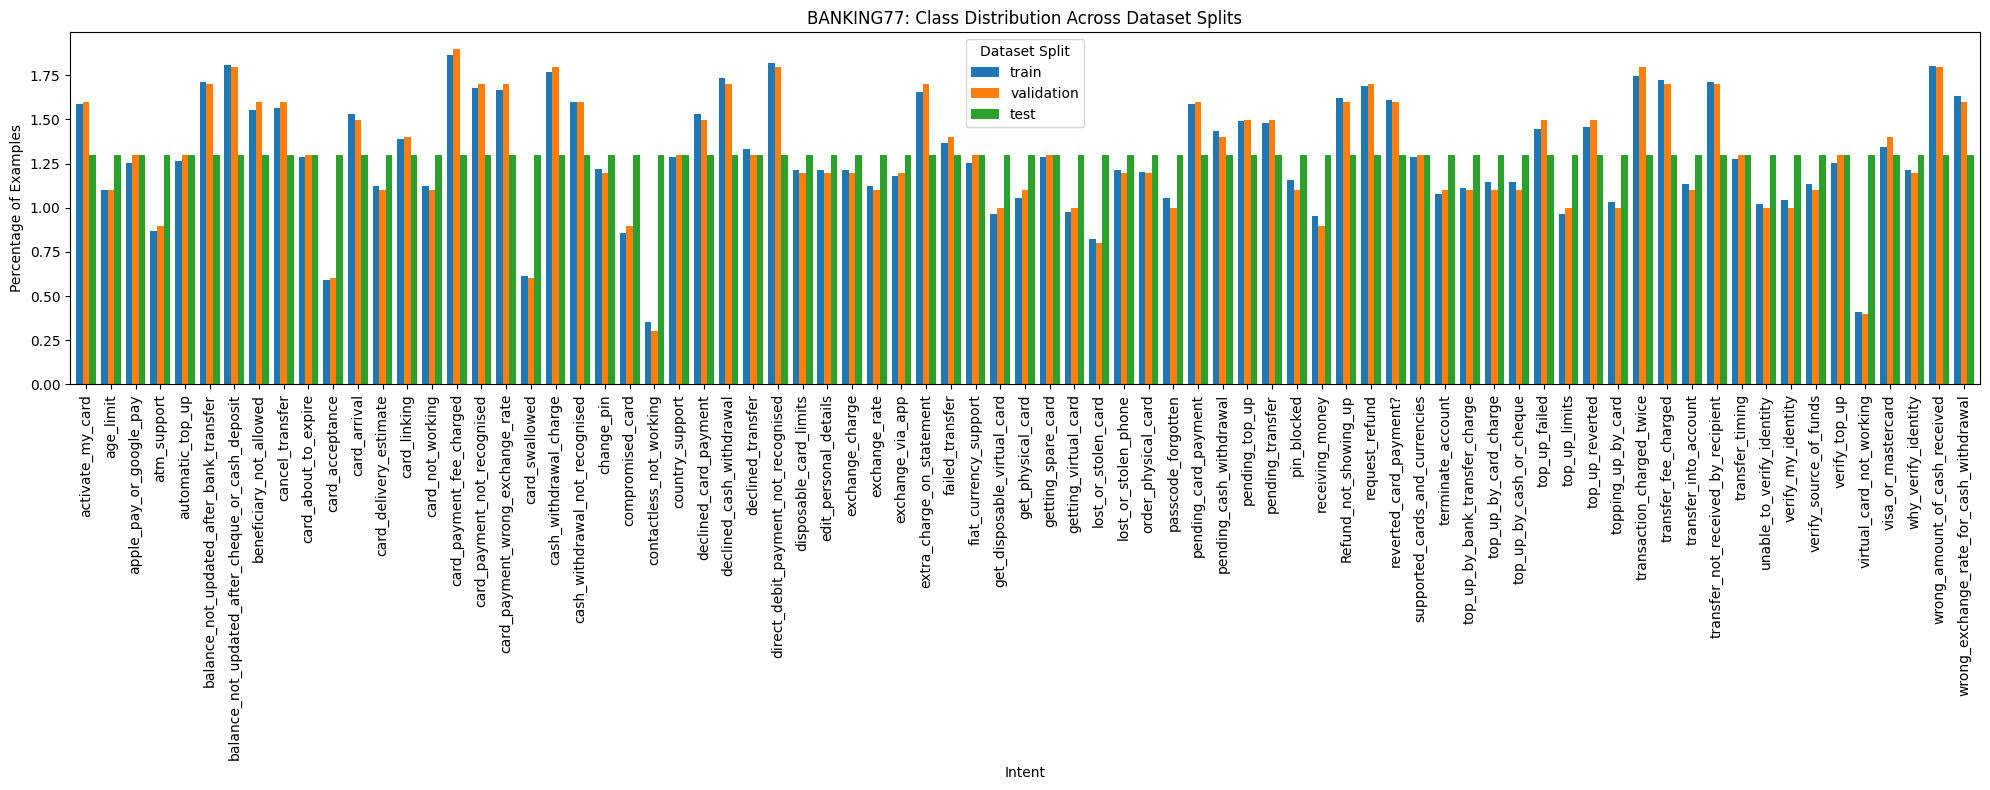

In [19]:
import matplotlib.pyplot as plt

distribution_comparison.plot(
    kind="bar",
    figsize=(20, 8),
    width=0.8
)

plt.title("BANKING77: Class Distribution Across Dataset Splits")
plt.xlabel("Intent")
plt.ylabel("Percentage of Examples")
plt.xticks(rotation=90)
plt.legend(title="Dataset Split")
plt.tight_layout()
plt.show()

In [20]:
train_texts = set(final_ds["train"]["text"])
validation_texts = set(final_ds["validation"]["text"])
test_texts = set(final_ds["test"]["text"])

train_val_overlap = train_texts.intersection(validation_texts)
train_test_overlap = train_texts.intersection(test_texts)
val_test_overlap = validation_texts.intersection(test_texts)

print("Train-Validation overlap:", len(train_val_overlap))
print("Train-Test overlap:", len(train_test_overlap))
print("Validation-Test overlap:", len(val_test_overlap))

assert len(train_val_overlap) == 0
assert len(train_test_overlap) == 0
assert len(val_test_overlap) == 0

print("\nNo exact query overlap detected!")

Train-Validation overlap: 0
Train-Test overlap: 0
Validation-Test overlap: 0

No exact query overlap detected!


In [21]:
from google.colab import drive

drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [22]:
import os
import shutil

SAVE_PATH = "/content/drive/MyDrive/Banking77_LoRA/dataset"

if os.path.exists(SAVE_PATH):
    shutil.rmtree(SAVE_PATH)

os.makedirs(os.path.dirname(SAVE_PATH), exist_ok=True)

final_ds.save_to_disk(SAVE_PATH)

print("Dataset successfully saved!")
print("Location:", SAVE_PATH)

Saving the dataset (0/1 shards):   0%|          | 0/9002 [00:00<?, ? examples/s]

Saving the dataset (0/1 shards):   0%|          | 0/1001 [00:00<?, ? examples/s]

Saving the dataset (0/1 shards):   0%|          | 0/3080 [00:00<?, ? examples/s]

Dataset successfully saved!
Location: /content/drive/MyDrive/Banking77_LoRA/dataset


In [23]:
from datasets import load_from_disk

loaded_ds = load_from_disk(SAVE_PATH)

print(loaded_ds)

for split in loaded_ds.keys():
    assert len(loaded_ds[split]) == len(final_ds[split])

print("\nDataset successfully saved and reloaded!")

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 9002
    })
    validation: Dataset({
        features: ['text', 'label'],
        num_rows: 1001
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 3080
    })
})

Dataset successfully saved and reloaded!


In [24]:
assert len(final_ds["train"]) == 9002
assert len(final_ds["validation"]) == 1001
assert len(final_ds["test"]) == 3080

for split in ["train", "validation", "test"]:
    assert len(set(final_ds[split]["label"])) == 77

assert len(train_val_overlap) == 0
assert len(train_test_overlap) == 0
assert len(val_test_overlap) == 0

print("PHASE 2: ALL CHECKS PASSED")

PHASE 2: ALL CHECKS PASSED


## Base Model Evaluation (Qwen2.5-0.5B-Instruct)

In [25]:
import os
import gc
import json
import re
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
import seaborn as sns

from datasets import load_from_disk
from transformers import (
    AutoTokenizer,
    AutoModelForCausalLM
)

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# Reproducibility
SEED = 42

np.random.seed(SEED)
torch.manual_seed(SEED)

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

    gpu_memory = (
        torch.cuda.get_device_properties(0).total_memory
        / (1024 ** 3)
    )

    print(f"GPU memory: {gpu_memory:.2f} GB")
else:
    raise RuntimeError(
        "GPU not available. Go to Runtime > Change runtime type "
        "and select a GPU."
    )

PyTorch version: 2.14.1+cu130
CUDA available: True
GPU: Tesla T4
GPU memory: 14.56 GB


In [26]:
from google.colab import drive

drive.mount('/content/drive')

DATASET_PATH = (
    "/content/drive/MyDrive/Banking77_LoRA/dataset"
)

final_ds = load_from_disk(DATASET_PATH)

# Extract actual intent names from dataset metadata
class_names = final_ds["train"].features["label"].names
NUM_CLASSES = len(class_names)
label_to_id = {label: idx for idx, label in enumerate(class_names)}

print(final_ds)

print("\nNumber of intent classes:", NUM_CLASSES)
print("Test examples:", len(final_ds["test"]))

assert NUM_CLASSES == 77
assert len(final_ds["test"]) == 3080

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 9002
    })
    validation: Dataset({
        features: ['text', 'label'],
        num_rows: 1001
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 3080
    })
})

Number of intent classes: 77
Test examples: 3080


In [27]:
import torch
import transformers
import huggingface_hub
import peft

print("PyTorch:", torch.__version__)
print("Transformers:", transformers.__version__)
print("Hugging Face Hub:", huggingface_hub.__version__)
print("PEFT:", peft.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch: 2.14.1+cu130
Transformers: 4.48.3
Hugging Face Hub: 0.28.1
PEFT: 0.14.0
CUDA available: True
GPU: Tesla T4


In [28]:
# Load the base model and tokenizer
MODEL_ID = "Qwen/Qwen2.5-0.5B-Instruct"

# Load tokenizer
tokenizer = AutoTokenizer.from_pretrained(
    MODEL_ID
)

# Left padding is recommended for batched causal LM generation
tokenizer.padding_side = "left"

if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token

# Load base model in FP16
model = AutoModelForCausalLM.from_pretrained(
    MODEL_ID,
    torch_dtype=torch.float16,
    device_map="auto",
    low_cpu_mem_usage=True
)

model.eval()

model.config.pad_token_id = tokenizer.pad_token_id

print("Base model loaded successfully!")
print("Model:", MODEL_ID)

print(
    "Total parameters:",
    f"{sum(p.numel() for p in model.parameters()):,}"
)

print("Device:", model.device)
print("Data type:", model.dtype)

Base model loaded successfully!
Model: Qwen/Qwen2.5-0.5B-Instruct
Total parameters: 494,032,768
Device: cuda:0
Data type: torch.float16


In [29]:
# ------------------------------------------
# ALLOWED INTENT LABELS
# ------------------------------------------

ALLOWED_LABELS = ", ".join(class_names)


# ------------------------------------------
# SYSTEM PROMPT
# ------------------------------------------

SYSTEM_PROMPT = """
You are a banking customer intent classifier.

Classify the customer's query into exactly ONE of
the allowed banking intent labels.

Return only the exact intent label.

Do not provide explanations.
Do not repeat the instructions.
Do not invent new labels.
""".strip()


# ------------------------------------------
# PROMPT GENERATION FUNCTION
# ------------------------------------------

def create_classification_prompt(query):

    messages = [

        {
            "role": "system",
            "content": SYSTEM_PROMPT
        },

        {
            "role": "user",
            "content": (
                f"Allowed labels: {ALLOWED_LABELS}\n\n"

                f"Customer query: {query}\n\n"

                "Return only the correct intent label."
            )
        }

    ]

    prompt = tokenizer.apply_chat_template(
        messages,

        tokenize=False,

        add_generation_prompt=True
    )

    return prompt


# ------------------------------------------
# INSPECT SAMPLE PROMPT
# ------------------------------------------

sample_query = final_ds["test"][0]["text"]

print("Customer query:")

print(sample_query)

print("\nClassification prompt:")

print(create_classification_prompt(sample_query))

Customer query:
How do I locate my card?

Classification prompt:
<|im_start|>system
You are a banking customer intent classifier.

Classify the customer's query into exactly ONE of
the allowed banking intent labels.

Return only the exact intent label.

Do not provide explanations.
Do not repeat the instructions.
Do not invent new labels.<|im_end|>
<|im_start|>user
Allowed labels: activate_my_card, age_limit, apple_pay_or_google_pay, atm_support, automatic_top_up, balance_not_updated_after_bank_transfer, balance_not_updated_after_cheque_or_cash_deposit, beneficiary_not_allowed, cancel_transfer, card_about_to_expire, card_acceptance, card_arrival, card_delivery_estimate, card_linking, card_not_working, card_payment_fee_charged, card_payment_not_recognised, card_payment_wrong_exchange_rate, card_swallowed, cash_withdrawal_charge, cash_withdrawal_not_recognised, change_pin, compromised_card, contactless_not_working, country_support, declined_card_payment, declined_cash_withdrawal, decline

In [30]:
# ==========================================
# PART 1: VERIFY PROMPT LENGTH
# ==========================================

MAX_INPUT_LENGTH = 1024

prompt_lengths = []

for query in tqdm(
    final_ds["test"]["text"],

    desc="Checking prompt lengths"
):

    prompt = create_classification_prompt(query)

    token_count = len(
        tokenizer(
            prompt,

            add_special_tokens=False
        )["input_ids"]
    )

    prompt_lengths.append(token_count)


print("\nPrompt length statistics")

print("-" * 40)

print("Minimum tokens:", min(prompt_lengths))

print("Maximum tokens:", max(prompt_lengths))

print(
    "Average tokens:",
    round(np.mean(prompt_lengths), 2)
)

print("Maximum allowed tokens:", MAX_INPUT_LENGTH)


# Ensure no prompt is silently truncated
assert max(prompt_lengths) <= MAX_INPUT_LENGTH, (
    "Some prompts exceed the allowed input length. "
    "Increase MAX_INPUT_LENGTH before inference."
)

print("\nAll prompts fit without truncation!")


# ==========================================
# PART 2: LABEL NORMALIZATION
# ==========================================

def normalize_label(text):

    text = text.strip().lower()

    # Remove prefixes
    text = re.sub(
        r"^(intent|label)\s*[:=-]\s*",
        "",
        text
    )

    # Remove surrounding formatting
    text = text.strip(" `\"'.,:;!?()[]{}")

    # Normalize spaces and hyphens
    text = text.replace(" ", "_")

    text = text.replace("-", "_")

    # Remove remaining punctuation
    text = re.sub(
        r"[^a-z0-9_]",
        "",
        text
    )

    return text


# Create normalized label mapping
normalized_label_map = {

    normalize_label(label): label

    for label in class_names

}


# ==========================================
# PART 3: EXTRACT INTENT
# ==========================================

def extract_intent(raw_output):

    text = raw_output.strip()

    # Try matching the first generated line
    first_line = text.split("\n")[0]

    normalized = normalize_label(first_line)

    if normalized in normalized_label_map:

        return normalized_label_map[normalized]


    # Search the original response for an exact label.
    # Keep spaces and punctuation intact so that labels
    # are not accidentally surrounded by artificial underscores.

    searchable_text = text.lower()

    matches = []

    for key, original_label in normalized_label_map.items():

        pattern = (
            rf"(?<![a-z0-9_])"
            rf"{re.escape(key)}"
            rf"(?![a-z0-9_])"
        )

        if re.search(pattern, searchable_text):

            matches.append(original_label)


    # Accept only one unambiguous match
    if len(matches) == 1:

        return matches[0]


    # Invalid or ambiguous response
    return "__invalid__"


# ==========================================
# PART 4: TEST EXTRACTION FUNCTION
# ==========================================

test_outputs = [

    "card_arrival",

    "The correct intent is card_arrival.",

    "cash_withdrawal_charge",

    "Refund_not_showing_up",

    "reverted_card_payment?",

    "some_unknown_category"

]

print("\nLabel extraction tests")

print("-" * 50)

for output in test_outputs:

    print(
        repr(output),
        "->",
        extract_intent(output)
    )

Checking prompt lengths:   0%|          | 0/3080 [00:00<?, ?it/s]


Prompt length statistics
----------------------------------------
Minimum tokens: 451
Maximum tokens: 526
Average tokens: 460.73
Maximum allowed tokens: 1024

All prompts fit without truncation!

Label extraction tests
--------------------------------------------------
'card_arrival' -> card_arrival
'The correct intent is card_arrival.' -> card_arrival
'cash_withdrawal_charge' -> cash_withdrawal_charge
'Refund_not_showing_up' -> Refund_not_showing_up
'reverted_card_payment?' -> reverted_card_payment?
'some_unknown_category' -> __invalid__


In [31]:
from tqdm.auto import tqdm

def generate_predictions(
    texts,

    batch_size=4,

    max_new_tokens=32
):

    all_raw_outputs = []

    all_predictions = []


    # Process data in batches
    for start in tqdm(
        range(0, len(texts), batch_size),

        desc="Generating predictions"
    ):

        batch_texts = texts[
            start:start + batch_size
        ]


        # Create prompts
        prompts = [

            create_classification_prompt(text)

            for text in batch_texts

        ]


        # Tokenize without truncation
        inputs = tokenizer(

            prompts,

            return_tensors="pt",

            padding=True,

            truncation=False

        )


        # Verify input length
        input_length = inputs["input_ids"].shape[1]

        if input_length > MAX_INPUT_LENGTH:

            raise ValueError(
                f"Input length {input_length} exceeds "
                f"maximum allowed length {MAX_INPUT_LENGTH}"
            )


        # Move inputs to GPU
        inputs = {

            key: value.to(model.device)

            for key, value in inputs.items()

        }


        with torch.inference_mode():

            outputs = model.generate(

                **inputs,

                max_new_tokens=max_new_tokens,

                do_sample=False,

                num_beams=1,

                pad_token_id=tokenizer.pad_token_id,

                eos_token_id=tokenizer.eos_token_id,

                use_cache=True

            )


        # Extract only newly generated tokens
        generated_tokens = outputs[:, input_length:]


        # Decode model output
        decoded_outputs = tokenizer.batch_decode(

            generated_tokens,

            skip_special_tokens=True

        )


        # Extract intent labels
        for raw_output in decoded_outputs:

            prediction = extract_intent(raw_output)

            all_raw_outputs.append(raw_output)

            all_predictions.append(prediction)


        # Release temporary tensors
        del inputs

        del outputs

        del generated_tokens


    return all_raw_outputs, all_predictions

In [32]:
# Use a conservative batch size for Colab T4
BATCH_SIZE = 4

print("Selected batch size:", BATCH_SIZE)


# Select 16 test examples
smoke_texts = final_ds["test"]["text"][:16]


# Generate predictions
smoke_raw, smoke_predictions = generate_predictions(

    smoke_texts,

    batch_size=BATCH_SIZE,

    max_new_tokens=32

)


# ==========================================
# DISPLAY RESULTS
# ==========================================

smoke_valid = 0

smoke_correct = 0

for i in range(len(smoke_texts)):

    actual_id = final_ds["test"][i]["label"]

    actual = class_names[actual_id]

    predicted = smoke_predictions[i]

    if predicted != "__invalid__":

        smoke_valid += 1

    if actual == predicted:

        smoke_correct += 1


    print("\n" + "=" * 70)

    print("Example:", i + 1)

    print("Query:", smoke_texts[i])

    print("Actual:", actual)

    print("Predicted:", predicted)

    print("Raw output:", repr(smoke_raw[i]))

    print("Correct:", actual == predicted)


# ==========================================
# SMOKE TEST SUMMARY
# ==========================================

print("\n" + "=" * 70)

print("SMOKE TEST SUMMARY")

print("=" * 70)

print("Total examples:", len(smoke_texts))

print("Valid predictions:", smoke_valid)

print("Invalid predictions:", len(smoke_texts) - smoke_valid)

print("Correct predictions:", smoke_correct)

print(
    "Valid prediction rate:",
    f"{smoke_valid / len(smoke_texts) * 100:.2f}%"
)

print(
    "Accuracy:",
    f"{smoke_correct / len(smoke_texts) * 100:.2f}%"
)

Selected batch size: 4


Generating predictions:   0%|          | 0/4 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/transformers/generation/configuration_utils.py:628: UserWarning: `do_sample` is set to `False`. However, `temperature` is set to `0.7` -- this flag is only used in sample-based generation modes. You should set `do_sample=True` or unset `temperature`.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/transformers/generation/configuration_utils.py:633: UserWarning: `do_sample` is set to `False`. However, `top_p` is set to `0.8` -- this flag is only used in sample-based generation modes. You should set `do_sample=True` or unset `top_p`.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/transformers/generation/configuration_utils.py:650: UserWarning: `do_sample` is set to `False`. However, `top_k` is set to `20` -- this flag is only used in sample-based generation modes. You should set `do_sample=True` or unset `top_k`.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/transformers/generation/configuration_utils.py:628: UserWarni


Example: 1
Query: How do I locate my card?
Actual: card_arrival
Predicted: __invalid__
Raw output: 'locate_card'
Correct: False

Example: 2
Query: I still have not received my new card, I ordered over a week ago.
Actual: card_arrival
Predicted: pending_top_up
Raw output: 'pending_top_up'
Correct: False

Example: 3
Query: I ordered a card but it has not arrived. Help please!
Actual: card_arrival
Predicted: pending_top_up
Raw output: 'pending_top_up'
Correct: False

Example: 4
Query: Is there a way to know when my card will arrive?
Actual: card_arrival
Predicted: pending_top_up
Raw output: 'pending_top_up'
Correct: False

Example: 5
Query: My card has not arrived yet.
Actual: card_arrival
Predicted: pending_top_up
Raw output: 'pending_top_up'
Correct: False

Example: 6
Query: When will I get my card?
Actual: card_arrival
Predicted: pending_top_up
Raw output: 'pending_top_up'
Correct: False

Example: 7
Query: Do you know if there is a tracking number for the new card you sent me?
Actual:

#### Run inference on the complete test set

In [33]:
# EXTRACT TEST DATA
test_texts = final_ds["test"]["text"]

y_true = np.array(
    final_ds["test"]["label"]
)


# GENERATE BASE MODEL PREDICTIONS
base_raw_outputs, base_predictions = generate_predictions(
    test_texts,
    batch_size=BATCH_SIZE,
    max_new_tokens=32
)


# CONVERT PREDICTIONS TO LABEL IDS

# Invalid predictions are assigned -1
# and are counted as incorrect.

y_pred = np.array([

    label_to_id.get(prediction, -1)

    for prediction in base_predictions

])


# VERIFY INFERENCE

print("\nBaseline inference completed!")

print("Total test examples:", len(y_true))

print("Total predictions:", len(y_pred))

print("Valid predictions:", np.sum(y_pred != -1))

print("Invalid predictions:", np.sum(y_pred == -1))


assert len(y_true) == len(y_pred) == 3080

assert len(base_raw_outputs) == len(y_true)

assert len(base_predictions) == len(y_true)

print("\nAll test predictions generated successfully!")

Generating predictions:   0%|          | 0/770 [00:00<?, ?it/s]


Baseline inference completed!
Total test examples: 3080
Total predictions: 3080
Valid predictions: 2264
Invalid predictions: 816

All test predictions generated successfully!


#### Calculate evaluation metrics

In [34]:
# All 77 class IDs
all_labels = list(range(NUM_CLASSES))

# Calculate metrics
baseline_accuracy = accuracy_score(
    y_true,
    y_pred
)

baseline_macro_f1 = f1_score(
    y_true,
    y_pred,
    labels=all_labels,
    average="macro",
    zero_division=0
)

baseline_weighted_f1 = f1_score(
    y_true,
    y_pred,
    labels=all_labels,
    average="weighted",
    zero_division=0
)

invalid_count = int(
    np.sum(y_pred == -1)
)

valid_count = int(
    np.sum(y_pred != -1)
)


invalid_prediction_rate = (
    invalid_count / len(y_true)
)

baseline_metrics = {

    "model": MODEL_ID,

    "dataset": "PolyAI/banking77",

    "test_examples": len(y_true),

    "num_classes": NUM_CLASSES,

    "accuracy": float(baseline_accuracy),

    "macro_f1": float(baseline_macro_f1),

    "weighted_f1": float(baseline_weighted_f1),

    "valid_predictions": valid_count,

    "invalid_predictions": invalid_count,

    "invalid_prediction_rate": float(
        invalid_prediction_rate
    )
}


print("=" * 60)
print("BASE MODEL EVALUATION RESULTS")
print("=" * 60)

for metric, value in baseline_metrics.items():

    if isinstance(value, float):
        print(f"{metric:30s}: {value:.4f}")

    else:
        print(f"{metric:30s}: {value}")

BASE MODEL EVALUATION RESULTS
model                         : Qwen/Qwen2.5-0.5B-Instruct
dataset                       : PolyAI/banking77
test_examples                 : 3080
num_classes                   : 77
accuracy                      : 0.1893
macro_f1                      : 0.1897
weighted_f1                   : 0.1897
valid_predictions             : 2264
invalid_predictions           : 816
invalid_prediction_rate       : 0.2649


#### Classification report

In [35]:
report = classification_report(
    y_true,
    y_pred,

    labels=all_labels,

    target_names=class_names,

    zero_division=0,

    output_dict=True
)

report_df = pd.DataFrame(report).transpose()

print("Classification report:")
display(
    report_df.round(4)
)

Classification report:


,precision,recall,f1-score,support
activate_my_card,0.8293,0.8500,0.8395,40.0
age_limit,1.0000,0.6500,0.7879,40.0
apple_pay_or_google_pay,1.0000,0.0750,0.1395,40.0
atm_support,0.8333,0.2500,0.3846,40.0
automatic_top_up,1.0000,0.0500,0.0952,40.0
...,...,...,...,...
wrong_amount_of_cash_received,0.0000,0.0000,0.0000,40.0
wrong_exchange_rate_for_cash_withdrawal,0.5000,0.2000,0.2857,40.0
micro avg,0.2575,0.1893,0.2182,3080.0
macro avg,0.3585,0.1893,0.1897,3080.0


In [36]:
BASE_OUTPUT_DIR = (
    "/content/drive/MyDrive/Banking77_LoRA/results"
)

os.makedirs(BASE_OUTPUT_DIR, exist_ok=True)

report_df.to_csv(
    f"{BASE_OUTPUT_DIR}/base_classification_report.csv"
)

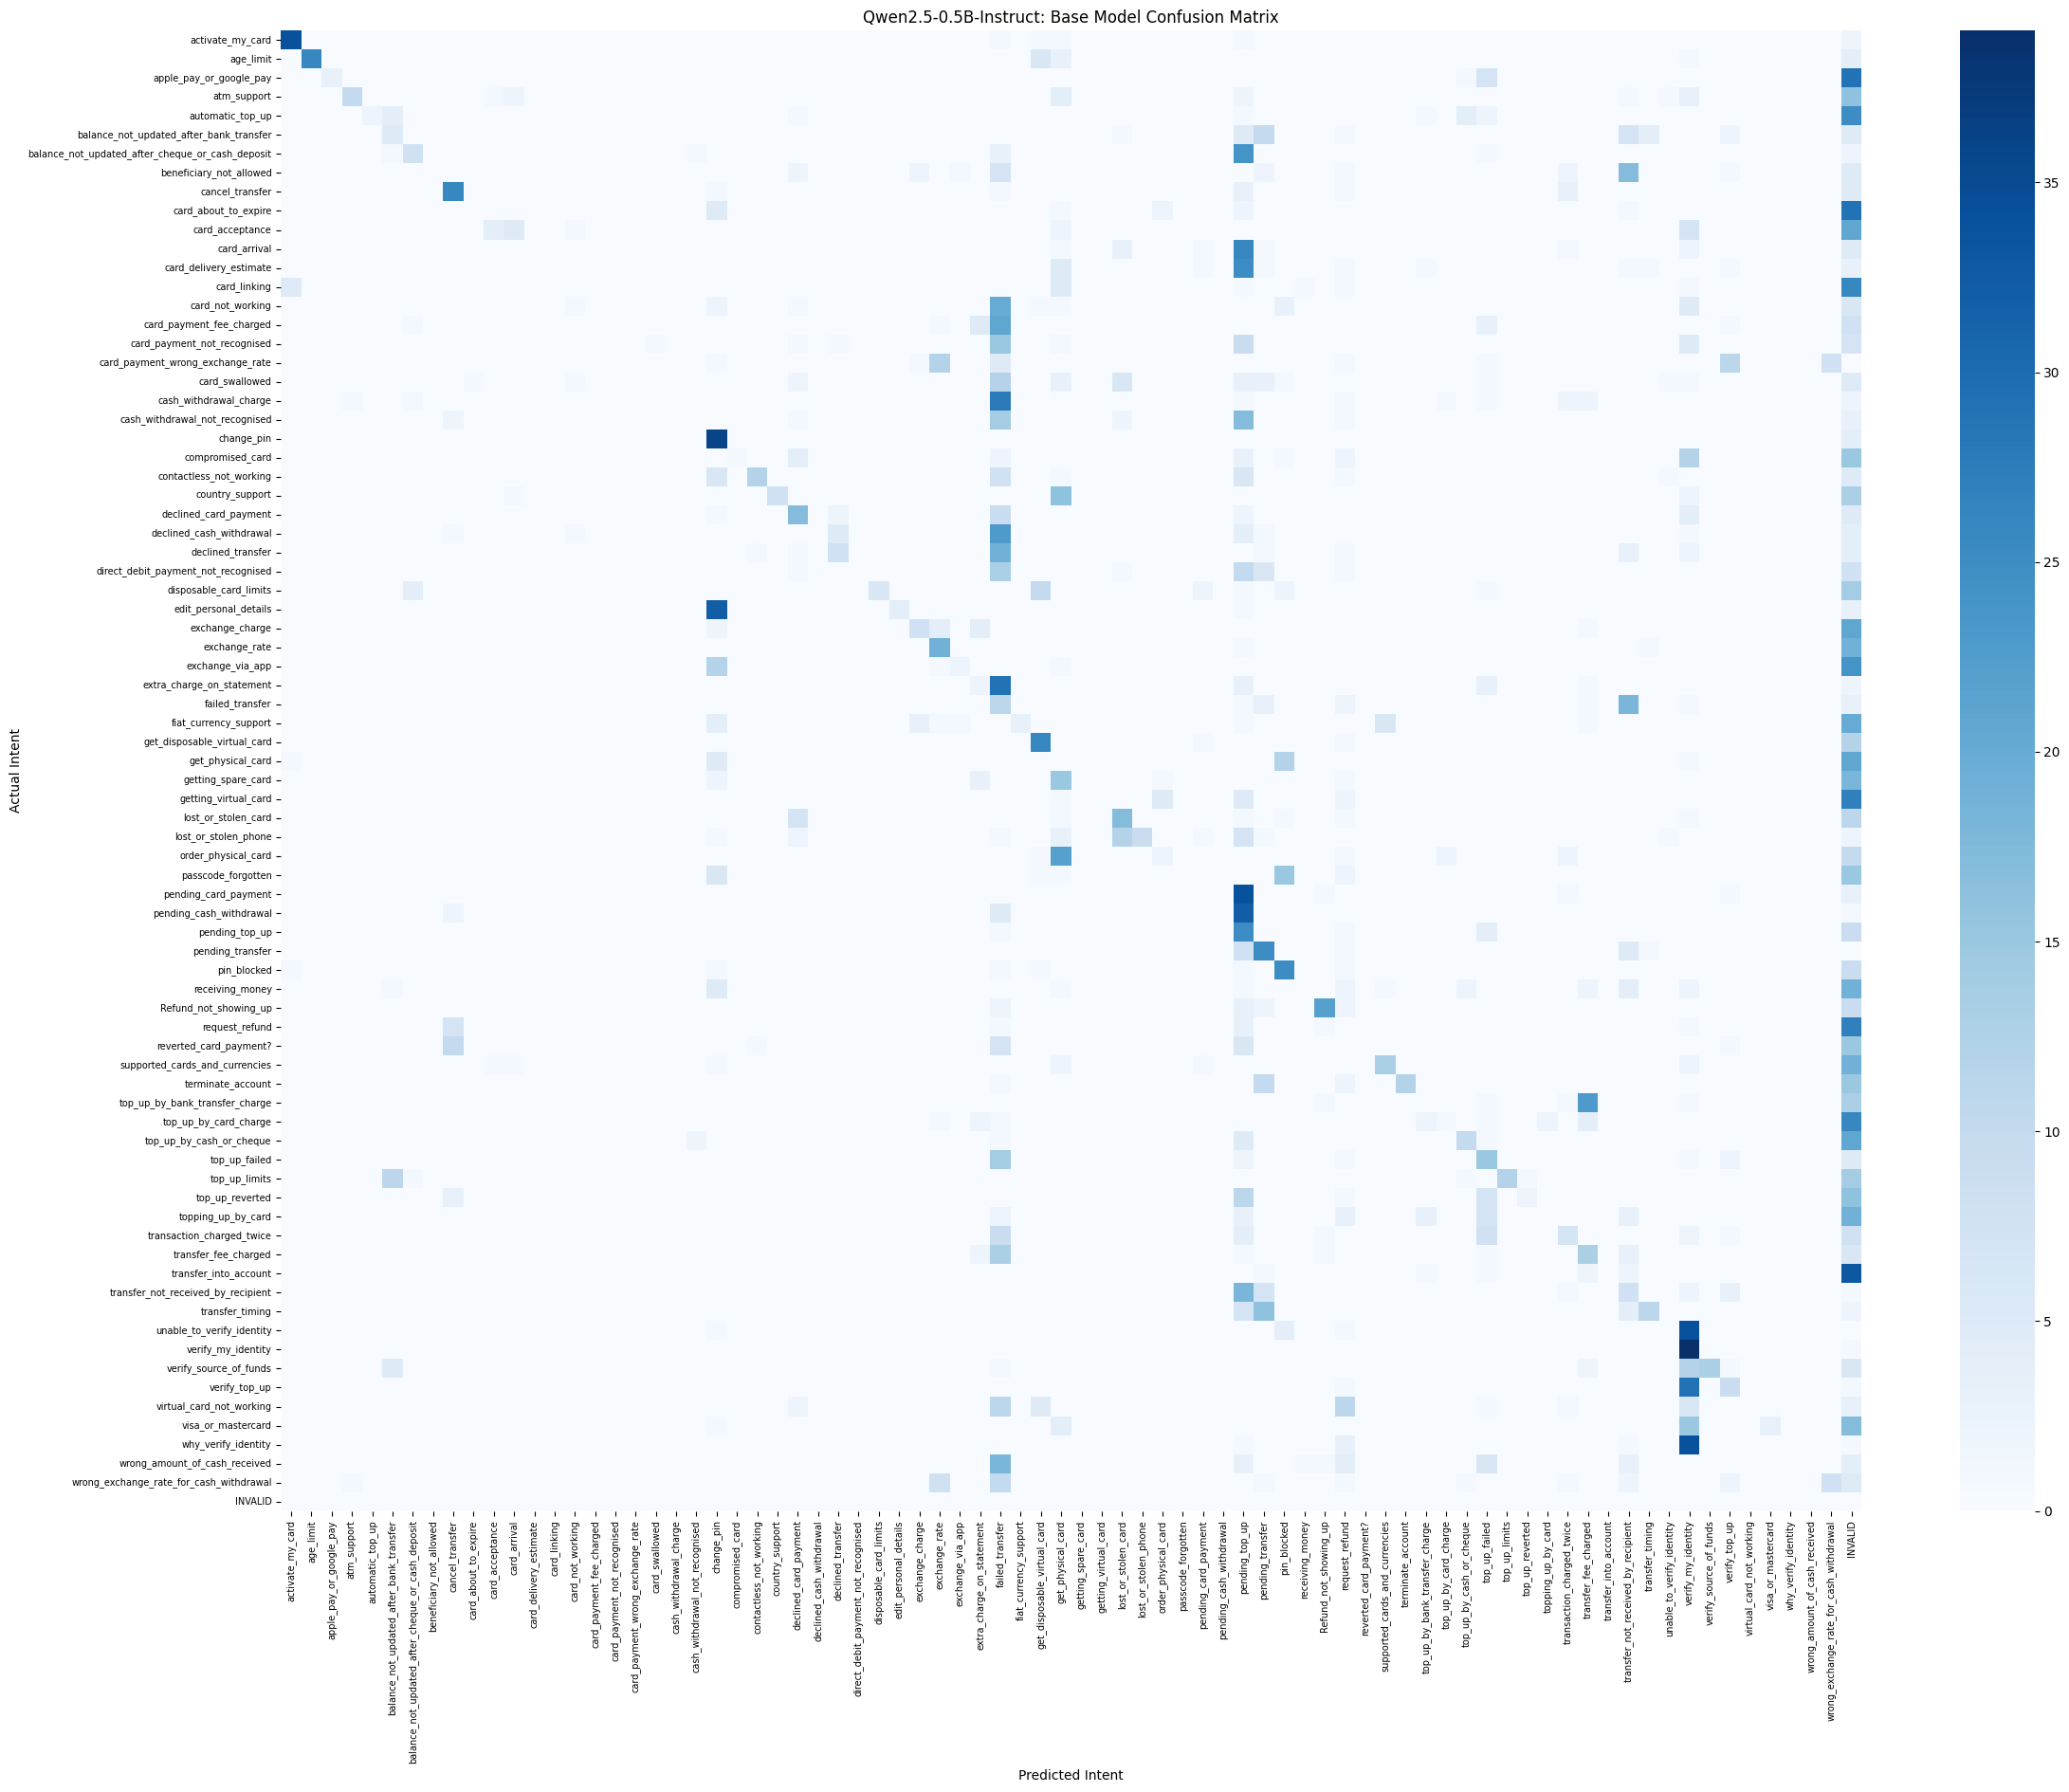

In [37]:
# CONFUSION MATRIX

# Add one additional class for invalid predictions
INVALID_LABEL_ID = NUM_CLASSES


# Replace invalid predictions (-1) with extra class ID
y_pred_for_cm = np.where(
    y_pred == -1,
    INVALID_LABEL_ID,
    y_pred
)


# Include all 77 classes plus INVALID
cm_labels = list(range(NUM_CLASSES + 1))

cm_names = class_names + ["INVALID"]


cm = confusion_matrix(
    y_true,
    y_pred_for_cm,
    labels=cm_labels
)

plt.figure(figsize=(24, 19))

sns.heatmap(
    cm,
    cmap="Blues",
    xticklabels=cm_names,
    yticklabels=cm_names
)

plt.title("Qwen2.5-0.5B-Instruct: Base Model Confusion Matrix")
plt.xlabel("Predicted Intent")
plt.ylabel("Actual Intent")

plt.xticks(rotation=90, fontsize=7)
plt.yticks(rotation=0, fontsize=7)

plt.tight_layout()

plt.savefig(
    f"{BASE_OUTPUT_DIR}/base_confusion_matrix.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

#### Save individual predictions

In [38]:
# ==========================================
# CREATE RESULTS DATAFRAME
# ==========================================

base_results = pd.DataFrame({

    "text": test_texts,

    "true_label_id": y_true,

    "true_intent": [

        class_names[i]

        for i in y_true

    ],

    "raw_output": base_raw_outputs,

    "predicted_intent": base_predictions,

    "predicted_label_id": y_pred,

    "correct": y_true == y_pred

})


# ==========================================
# SAVE PREDICTIONS
# ==========================================

base_results.to_csv(

    f"{BASE_OUTPUT_DIR}/base_model_predictions.csv",

    index=False

)


print("Baseline predictions saved!")

print("Total records:", len(base_results))


# Display sample predictions
display(

    base_results.head(10)

)

Baseline predictions saved!
Total records: 3080


,text,true_label_id,true_intent,raw_output,predicted_intent,predicted_label_id,correct
0,How do I locate my card?,11,card_arrival,locate_card,__invalid__,-1,False
1,"I still have not received my new card, I order...",11,card_arrival,pending_top_up,pending_top_up,47,False
2,I ordered a card but it has not arrived. Help ...,11,card_arrival,pending_top_up,pending_top_up,47,False
3,Is there a way to know when my card will arrive?,11,card_arrival,pending_top_up,pending_top_up,47,False
4,My card has not arrived yet.,11,card_arrival,pending_top_up,pending_top_up,47,False
5,When will I get my card?,11,card_arrival,pending_top_up,pending_top_up,47,False
6,Do you know if there is a tracking number for ...,11,card_arrival,tracking_number,__invalid__,-1,False
7,i have not received my card,11,card_arrival,pending_top_up,pending_top_up,47,False
8,still waiting on that card,11,card_arrival,pending_top_up,pending_top_up,47,False
9,Is it normal to have to wait over a week for m...,11,card_arrival,pending_top_up,pending_top_up,47,False


#### Save baseline metrics

In [39]:
with open(
    f"{BASE_OUTPUT_DIR}/baseline_metrics.json",
    "w"
) as f:

    json.dump(
        baseline_metrics,
        f,
        indent=4
    )


print("Baseline metrics saved successfully!")

print("\nSaved files:")

for filename in sorted(
    os.listdir(BASE_OUTPUT_DIR)
):

    print("-", filename)

Baseline metrics saved successfully!

Saved files:
- base_classification_report.csv
- base_confusion_matrix.png
- base_model_predictions.csv
- baseline_metrics.json


In [40]:
# Release base model from GPU memory
del model

gc.collect()

torch.cuda.empty_cache()

print("Base model unloaded successfully!")

print(
    "GPU memory allocated:",
    round(
        torch.cuda.memory_allocated() / (1024 ** 3),
        3
    ),
    "GB"
)

print(
    "GPU memory reserved:",
    round(
        torch.cuda.memory_reserved() / (1024 ** 3),
        3
    ),
    "GB"
)

Base model unloaded successfully!
GPU memory allocated: 0.008 GB
GPU memory reserved: 0.02 GB


In [41]:
# Select examples where prediction was incorrect
failure_df = base_results[
    base_results["correct"] == False
].copy()

# Prioritize invalid predictions to inspect formatting failures
invalid_failures = failure_df[
    failure_df["predicted_intent"] == "__invalid__"
]

# Select up to 3 invalid examples
failure_examples = invalid_failures.head(3)

# If fewer than 3 invalid examples, fill with other mistakes
if len(failure_examples) < 3:

    remaining = failure_df[
        failure_df["predicted_intent"] != "__invalid__"
    ]

    failure_examples = pd.concat([
        failure_examples,
        remaining.head(3 - len(failure_examples))
    ])

display(
    failure_examples[
        [
            "text",
            "true_intent",
            "raw_output",
            "predicted_intent"
        ]
    ]
)

failure_examples.to_csv(
    f"{BASE_OUTPUT_DIR}/base_failure_examples.csv",
    index=False
)

print("Three failure examples saved.")

,text,true_intent,raw_output,predicted_intent
0,How do I locate my card?,card_arrival,locate_card,__invalid__
6,Do you know if there is a tracking number for ...,card_arrival,tracking_number,__invalid__
10,How do I track my card?,card_arrival,track_card,__invalid__


Three failure examples saved.


## LoRA fine-tuning

In [42]:
import os
import shutil
import gc
import json
import inspect

import numpy as np
import pandas as pd
import torch

from datasets import load_from_disk

from transformers import (
    AutoTokenizer,
    AutoModelForCausalLM,
    Trainer,
    TrainingArguments
)

from peft import (
    LoraConfig,
    get_peft_model,
    TaskType
)

from torch.utils.data import Dataset


# ------------------------------------------
# REPRODUCIBILITY
# ------------------------------------------

SEED = 42

np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)


# ------------------------------------------
# ENVIRONMENT CHECK
# ------------------------------------------

print("PyTorch:", torch.__version__)

print("CUDA available:", torch.cuda.is_available())

if not torch.cuda.is_available():
    raise RuntimeError("GPU is required for this experiment.")

print("GPU:", torch.cuda.get_device_name(0))

print(
    "Available GPU memory:",
    round(
        torch.cuda.get_device_properties(0).total_memory
        / (1024 ** 3),
        2
    ),
    "GB"
)

print("\nPEFT imported successfully!")

PyTorch: 2.14.1+cu130
CUDA available: True
GPU: Tesla T4
Available GPU memory: 14.56 GB

PEFT imported successfully!


#### Define LoRA configuration

In [43]:
# ------------------------------------------
# MODEL AND DATASET CONFIGURATION
# ------------------------------------------

MODEL_ID = "Qwen/Qwen2.5-0.5B-Instruct"

# ------------------------------------------
# LORA HYPERPARAMETERS
# ------------------------------------------

LORA_R = 16

LORA_ALPHA = 32

LORA_DROPOUT = 0.05

TARGET_MODULES = [
    "q_proj",
    "k_proj",
    "v_proj",
    "o_proj"
]


# ------------------------------------------
# TRAINING HYPERPARAMETERS
# ------------------------------------------

LEARNING_RATE = 2e-4

NUM_EPOCHS = 3

TRAIN_BATCH_SIZE = 4

EVAL_BATCH_SIZE = 4

GRADIENT_ACCUMULATION_STEPS = 4

MAX_SEQ_LENGTH = 640

WEIGHT_DECAY = 0.01

WARMUP_RATIO = 0.03


# ------------------------------------------
# OUTPUT DIRECTORIES
# ------------------------------------------

BASE_OUTPUT_DIR = (
    "/content/drive/MyDrive/Banking77_LoRA/results"
)

TRAINING_OUTPUT_DIR = (
    "/content/drive/MyDrive/Banking77_LoRA/lora_training"
)

LORA_ADAPTER_DIR = (
    "/content/drive/MyDrive/Banking77_LoRA/lora_adapter"
)

for output_dir in [TRAINING_OUTPUT_DIR, LORA_ADAPTER_DIR]:
    if os.path.exists(output_dir):
        shutil.rmtree(output_dir)

os.makedirs(BASE_OUTPUT_DIR, exist_ok=True)
os.makedirs(TRAINING_OUTPUT_DIR, exist_ok=True)
os.makedirs(LORA_ADAPTER_DIR, exist_ok=True)


# ------------------------------------------
# DISPLAY CONFIGURATION
# ------------------------------------------

lora_config_summary = {

    "model": MODEL_ID,

    "method": "LoRA",

    "rank": LORA_R,

    "alpha": LORA_ALPHA,

    "dropout": LORA_DROPOUT,

    "target_modules": TARGET_MODULES,

    "learning_rate": LEARNING_RATE,

    "epochs": NUM_EPOCHS,

    "train_batch_size": TRAIN_BATCH_SIZE,

    "gradient_accumulation_steps": (
        GRADIENT_ACCUMULATION_STEPS
    ),

    "effective_batch_size": (
        TRAIN_BATCH_SIZE
        * GRADIENT_ACCUMULATION_STEPS
    ),

    "max_sequence_length": MAX_SEQ_LENGTH,

    "weight_decay": WEIGHT_DECAY,

    "warmup_ratio": WARMUP_RATIO

}

print("LoRA configuration:")

print(
    json.dumps(
        lora_config_summary,
        indent=4
    )
)

LoRA configuration:
{
    "model": "Qwen/Qwen2.5-0.5B-Instruct",
    "method": "LoRA",
    "rank": 16,
    "alpha": 32,
    "dropout": 0.05,
    "target_modules": [
        "q_proj",
        "k_proj",
        "v_proj",
        "o_proj"
    ],
    "learning_rate": 0.0002,
    "epochs": 3,
    "train_batch_size": 4,
    "gradient_accumulation_steps": 4,
    "effective_batch_size": 16,
    "max_sequence_length": 640,
    "weight_decay": 0.01,
    "warmup_ratio": 0.03
}


#### Load tokenizer and base model for fine-tuning

In [44]:
# ------------------------------------------
# LOAD TOKENIZER
# ------------------------------------------

tokenizer = AutoTokenizer.from_pretrained(
    MODEL_ID
)

# Right padding is used during training
tokenizer.padding_side = "right"

if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token


# ------------------------------------------
# LOAD BASE MODEL
# ------------------------------------------

model = AutoModelForCausalLM.from_pretrained(

    MODEL_ID,

    torch_dtype=torch.float16,

    device_map="auto",

    low_cpu_mem_usage=True

)

model.config.pad_token_id = tokenizer.pad_token_id

# Disable cache during gradient checkpointing
model.config.use_cache = False


# ------------------------------------------
# ENABLE GRADIENT CHECKPOINTING
# ------------------------------------------

model.gradient_checkpointing_enable()

model.enable_input_require_grads()


# ------------------------------------------
# VERIFY MODEL
# ------------------------------------------

print("Base model loaded for LoRA fine-tuning!")

print("Model:", MODEL_ID)

print("Device:", model.device)

print("Data type:", model.dtype)

print(
    "Total parameters:",
    f"{sum(p.numel() for p in model.parameters()):,}"
)

print(
    "GPU memory allocated:",
    round(
        torch.cuda.memory_allocated() / (1024 ** 3),
        3
    ),
    "GB"
)

Base model loaded for LoRA fine-tuning!
Model: Qwen/Qwen2.5-0.5B-Instruct
Device: cuda:0
Data type: torch.float16
Total parameters: 494,032,768
GPU memory allocated: 0.936 GB


#### Apply LoRA adapters

In [45]:
# ------------------------------------------
# DEFINE LORA CONFIGURATION
# ------------------------------------------

peft_config = LoraConfig(

    r=LORA_R,

    lora_alpha=LORA_ALPHA,

    lora_dropout=LORA_DROPOUT,

    target_modules=TARGET_MODULES,

    bias="none",

    task_type=TaskType.CAUSAL_LM

)


# ------------------------------------------
# APPLY LORA
# ------------------------------------------

model = get_peft_model(
    model,
    peft_config
)


# ------------------------------------------
# DISPLAY TRAINABLE PARAMETERS
# ------------------------------------------

model.print_trainable_parameters()


# Calculate trainable and total parameters
trainable_parameters = sum(

    p.numel()

    for p in model.parameters()

    if p.requires_grad

)

total_parameters = sum(

    p.numel()

    for p in model.parameters()

)

trainable_percentage = (
    trainable_parameters / total_parameters
) * 100


print("\nParameter statistics")

print("-" * 40)

print(
    "Total parameters:",
    f"{total_parameters:,}"
)

print(
    "Trainable parameters:",
    f"{trainable_parameters:,}"
)

print(
    "Trainable percentage:",
    f"{trainable_percentage:.4f}%"
)

print(
    "Frozen parameters:",
    f"{total_parameters - trainable_parameters:,}"
)

trainable params: 2,162,688 || all params: 496,195,456 || trainable%: 0.4359

Parameter statistics
----------------------------------------
Total parameters: 496,195,456
Trainable parameters: 2,162,688
Trainable percentage: 0.4359%
Frozen parameters: 494,032,768


#### Prepare training and validation data

In [46]:
# ------------------------------------------
# VERIFY DATASET
# ------------------------------------------

assert len(final_ds["train"]) == 9002

assert len(final_ds["validation"]) == 1001

assert len(final_ds["test"]) == 3080

print("Training examples:", len(final_ds["train"]))

print("Validation examples:", len(final_ds["validation"]))

print("Test examples:", len(final_ds["test"]))


# ------------------------------------------
# TOKENIZATION FUNCTION
# ------------------------------------------

def preprocess_example(example):

    # Generate the same prompt used in Phase 3
    prompt = create_classification_prompt(
        example["text"]
    )

    # Expected intent label
    target_label = class_names[
        int(example["label"])
    ]

    # Tokenize prompt separately
    prompt_ids = tokenizer(

        prompt,

        add_special_tokens=False

    )["input_ids"]


    # Append the expected assistant response
    full_text = (
        prompt
        + target_label
        + tokenizer.eos_token
    )


    # Tokenize complete prompt and response
    encoded = tokenizer(

        full_text,

        add_special_tokens=False,

        truncation=False

    )

    input_ids = encoded["input_ids"]

    attention_mask = encoded["attention_mask"]


    # Do not silently truncate the expected answer
    if len(input_ids) > MAX_SEQ_LENGTH:

        raise ValueError(
            f"Sequence length {len(input_ids)} exceeds "
            f"MAX_SEQ_LENGTH={MAX_SEQ_LENGTH}"
        )


    # Verify prompt tokens match the beginning
    # of the complete input
    if input_ids[:len(prompt_ids)] != prompt_ids:

        raise ValueError(
            "Prompt tokenization mismatch. "
            "Check the chat template and tokenization."
        )


    # Mask prompt tokens from the training loss
    labels = (

        [-100] * len(prompt_ids)

        + input_ids[len(prompt_ids):]

    )


    return {

        "input_ids": input_ids,

        "attention_mask": attention_mask,

        "labels": labels

    }


# ------------------------------------------
# TOKENIZE TRAINING DATA
# ------------------------------------------

tokenized_train = final_ds["train"].map(

    preprocess_example,

    remove_columns=final_ds["train"].column_names,

    desc="Tokenizing training data"

)


# ------------------------------------------
# TOKENIZE VALIDATION DATA
# ------------------------------------------

tokenized_validation = final_ds["validation"].map(

    preprocess_example,

    remove_columns=final_ds["validation"].column_names,

    desc="Tokenizing validation data"

)


# ------------------------------------------
# VERIFY TOKENIZED DATA
# ------------------------------------------

print("\nTokenization completed!")

print("Training examples:", len(tokenized_train))

print("Validation examples:", len(tokenized_validation))

print(
    "Training example keys:",
    tokenized_train[0].keys()
)

print(
    "First training sequence length:",
    len(tokenized_train[0]["input_ids"])
)

print(
    "First training target tokens:",
    sum(
        1 for x in tokenized_train[0]["labels"]
        if x != -100
    )
)

assert len(tokenized_train) == 9002

assert len(tokenized_validation) == 1001

assert all(
    len(x["input_ids"]) <= MAX_SEQ_LENGTH
    for x in tokenized_train
)

assert all(
    len(x["input_ids"]) <= MAX_SEQ_LENGTH
    for x in tokenized_validation
)

print("\nTraining and validation datasets are ready!")

Training examples: 9002
Validation examples: 1001
Test examples: 3080


Tokenizing training data:   0%|          | 0/9002 [00:00<?, ? examples/s]

Tokenizing validation data:   0%|          | 0/1001 [00:00<?, ? examples/s]


Tokenization completed!
Training examples: 9002
Validation examples: 1001
Training example keys: dict_keys(['input_ids', 'attention_mask', 'labels'])
First training sequence length: 465
First training target tokens: 4

Training and validation datasets are ready!


#### Create data collator

In [47]:
class CausalLMDataCollator:

    def __init__(self, tokenizer):

        self.tokenizer = tokenizer

        self.pad_token_id = tokenizer.pad_token_id


    def __call__(self, features):

        max_length = max(

            len(feature["input_ids"])

            for feature in features

        )


        batch_input_ids = []

        batch_attention_mask = []

        batch_labels = []


        for feature in features:

            input_ids = feature["input_ids"]

            attention_mask = feature["attention_mask"]

            labels = feature["labels"]


            padding_length = (
                max_length - len(input_ids)
            )


            # Right padding
            padded_input_ids = (

                input_ids

                + [self.pad_token_id] * padding_length

            )


            padded_attention_mask = (

                attention_mask

                + [0] * padding_length

            )


            # Ignore padding positions in loss
            padded_labels = (

                labels

                + [-100] * padding_length

            )


            batch_input_ids.append(
                padded_input_ids
            )

            batch_attention_mask.append(
                padded_attention_mask
            )

            batch_labels.append(
                padded_labels
            )


        return {

            "input_ids": torch.tensor(
                batch_input_ids,
                dtype=torch.long
            ),

            "attention_mask": torch.tensor(
                batch_attention_mask,
                dtype=torch.long
            ),

            "labels": torch.tensor(
                batch_labels,
                dtype=torch.long
            )

        }


data_collator = CausalLMDataCollator(
    tokenizer
)


# ------------------------------------------
# TEST DATA COLLATOR
# ------------------------------------------

sample_batch = data_collator([

    tokenized_train[0],

    tokenized_train[1]

])


print("Data collator test successful!")

for key, value in sample_batch.items():

    print(
        key,
        value.shape,
        value.dtype
    )


assert (
    sample_batch["input_ids"].shape
    == sample_batch["labels"].shape
)

print("\nBatch preparation verified!")

Data collator test successful!
input_ids torch.Size([2, 465]) torch.int64
attention_mask torch.Size([2, 465]) torch.int64
labels torch.Size([2, 465]) torch.int64

Batch preparation verified!


#### Configure training arguments

In [48]:
# ------------------------------------------
# TRAINING ARGUMENTS
# ------------------------------------------

training_kwargs = {

    "output_dir": TRAINING_OUTPUT_DIR,

    "num_train_epochs": NUM_EPOCHS,

    "per_device_train_batch_size": TRAIN_BATCH_SIZE,

    "per_device_eval_batch_size": EVAL_BATCH_SIZE,

    "gradient_accumulation_steps": (
        GRADIENT_ACCUMULATION_STEPS
    ),

    "learning_rate": LEARNING_RATE,

    "weight_decay": WEIGHT_DECAY,

    "warmup_ratio": WARMUP_RATIO,

    "lr_scheduler_type": "cosine",

    "optim": "adamw_torch",

    "fp16": True,

    "bf16": False,

    "gradient_checkpointing": True,

    "logging_steps": 50,

    "save_strategy": "epoch",

    "load_best_model_at_end": True,

    "metric_for_best_model": "eval_loss",

    "greater_is_better": False,

    "save_total_limit": 2,

    "report_to": "none",

    "seed": SEED,

    "data_seed": SEED,

    "remove_unused_columns": False,

    "dataloader_pin_memory": True

}


# ------------------------------------------
# VERSION-COMPATIBLE EVALUATION STRATEGY
# ------------------------------------------

training_parameters = inspect.signature(
    TrainingArguments.__init__
).parameters


if "eval_strategy" in training_parameters:

    training_kwargs["eval_strategy"] = "epoch"

elif "evaluation_strategy" in training_parameters:

    training_kwargs["evaluation_strategy"] = "epoch"

else:

    raise RuntimeError(
        "Could not identify evaluation strategy parameter "
        "in the installed Transformers version."
    )


# ------------------------------------------
# CREATE TRAINING ARGUMENTS
# ------------------------------------------

training_args = TrainingArguments(
    **training_kwargs
)


print("Training arguments configured successfully!")

print("\nEpochs:", NUM_EPOCHS)

print("Learning rate:", LEARNING_RATE)

print("Training batch size:", TRAIN_BATCH_SIZE)

print("Gradient accumulation:", GRADIENT_ACCUMULATION_STEPS)

print(
    "Effective batch size:",
    TRAIN_BATCH_SIZE * GRADIENT_ACCUMULATION_STEPS
)

print("Evaluation strategy: epoch")

print("Best checkpoint metric: eval_loss")

Training arguments configured successfully!

Epochs: 3
Learning rate: 0.0002
Training batch size: 4
Gradient accumulation: 4
Effective batch size: 16
Evaluation strategy: epoch
Best checkpoint metric: eval_loss


#### Initialize Trainer

In [49]:
# ------------------------------------------
# PREPARE TRAINER ARGUMENTS
# ------------------------------------------

trainer_kwargs = {

    "model": model,

    "args": training_args,

    "train_dataset": tokenized_train,

    "eval_dataset": tokenized_validation,

    "data_collator": data_collator

}


# Handle tokenizer argument compatibility
trainer_parameters = inspect.signature(
    Trainer.__init__
).parameters


if "processing_class" in trainer_parameters:

    trainer_kwargs["processing_class"] = tokenizer

else:

    trainer_kwargs["tokenizer"] = tokenizer


# ------------------------------------------
# INITIALIZE TRAINER
# ------------------------------------------

trainer = Trainer(
    **trainer_kwargs
)


print("Trainer initialized successfully!")

print("Training examples:", len(tokenized_train))

print("Validation examples:", len(tokenized_validation))

print("LoRA training is ready to start.")

Trainer initialized successfully!
Training examples: 9002
Validation examples: 1001
LoRA training is ready to start.


#### Start LoRA fine-tuning

In [50]:
# ==========================================
# START TRAINING
# ==========================================

print("=" * 60)

print("STARTING LORA FINE-TUNING")

print("=" * 60)


train_result = trainer.train()


# ==========================================
# TRAINING SUMMARY
# ==========================================

print("\nTraining completed!")

print("=" * 60)

print("TRAINING METRICS")

print("=" * 60)


for key, value in train_result.metrics.items():

    print(f"{key:30s}: {value}")


# ==========================================
# SAVE TRAINING METRICS
# ==========================================

training_metrics = train_result.metrics

with open(

    f"{TRAINING_OUTPUT_DIR}/training_metrics.json",

    "w"

) as f:

    json.dump(

        training_metrics,

        f,

        indent=4,

        default=float

    )


print("\nTraining metrics saved!")

STARTING LORA FINE-TUNING


Epoch,Training Loss,Validation Loss
0,0.108600,0.121761
1,0.061200,0.078517
2,0.035800,0.076357



Training completed!
TRAINING METRICS
train_runtime                 : 4466.1262
train_samples_per_second      : 6.047
train_steps_per_second        : 0.378
total_flos                    : 2.78101773168384e+16
train_loss                    : 0.11914998116159496
epoch                         : 2.9986672589960017

Training metrics saved!


#### Evaluate on validation set

In [51]:
# ==========================================
# VALIDATION EVALUATION
# ==========================================

validation_metrics = trainer.evaluate()


print("=" * 60)

print("BEST MODEL VALIDATION RESULTS")

print("=" * 60)


for key, value in validation_metrics.items():

    print(f"{key:30s}: {value}")


# ==========================================
# SAVE VALIDATION METRICS
# ==========================================

with open(

    f"{TRAINING_OUTPUT_DIR}/validation_metrics.json",

    "w"

) as f:

    json.dump(

        validation_metrics,

        f,

        indent=4,

        default=float

    )


print("\nValidation metrics saved!")

BEST MODEL VALIDATION RESULTS
eval_loss                     : 0.07635703682899475
eval_runtime                  : 55.1607
eval_samples_per_second       : 18.147
eval_steps_per_second         : 4.55
epoch                         : 2.9986672589960017

Validation metrics saved!


#### Save the LoRA adapter

In [52]:
# ==========================================
# SAVE BEST LORA ADAPTER
# ==========================================

trainer.save_model(
    LORA_ADAPTER_DIR
)

tokenizer.save_pretrained(
    LORA_ADAPTER_DIR
)


# ==========================================
# SAVE CONFIGURATION
# ==========================================

with open(

    f"{LORA_ADAPTER_DIR}/experiment_config.json",

    "w"

) as f:

    json.dump(

        lora_config_summary,

        f,

        indent=4

    )


# ==========================================
# SAVE TRAINING HISTORY
# ==========================================

training_history = trainer.state.log_history

with open(

    f"{TRAINING_OUTPUT_DIR}/training_history.json",

    "w"

) as f:

    json.dump(

        training_history,

        f,

        indent=4

    )


print("LoRA adapter saved successfully!")

print("Adapter directory:", LORA_ADAPTER_DIR)

print("Training directory:", TRAINING_OUTPUT_DIR)

LoRA adapter saved successfully!
Adapter directory: /content/drive/MyDrive/Banking77_LoRA/lora_adapter
Training directory: /content/drive/MyDrive/Banking77_LoRA/lora_training


#### Plot training and validation loss

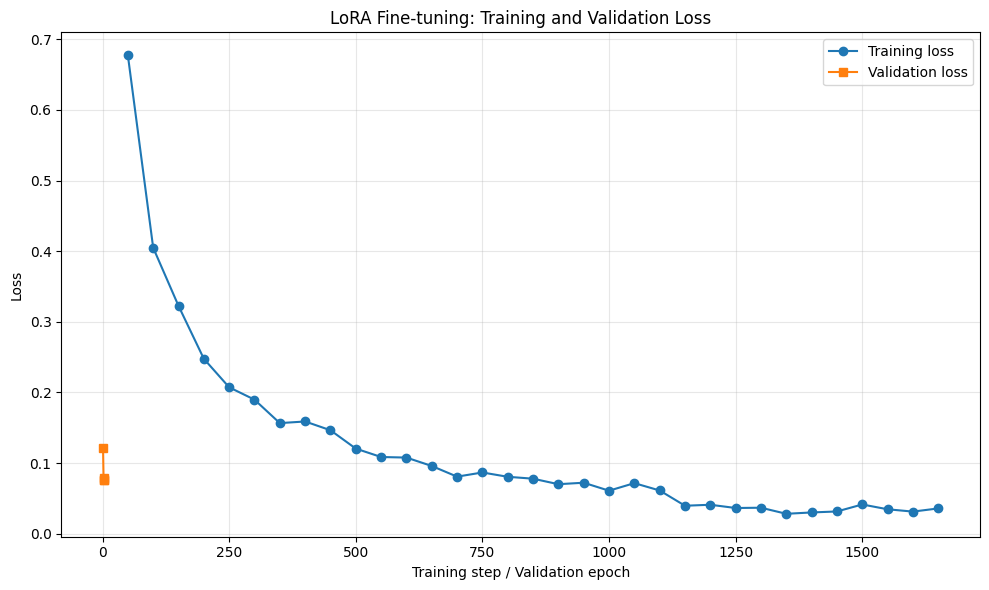

Loss curve saved successfully!


In [53]:
# ==========================================
# EXTRACT TRAINING HISTORY
# ==========================================

history = trainer.state.log_history

train_steps = []

train_losses = []

eval_epochs = []

eval_losses = []


for record in history:

    if "loss" in record and "eval_loss" not in record:

        train_steps.append(
            record.get("step", len(train_steps))
        )

        train_losses.append(
            record["loss"]
        )


    if "eval_loss" in record:

        eval_epochs.append(
            record.get("epoch", len(eval_epochs) + 1)
        )

        eval_losses.append(
            record["eval_loss"]
        )


# ==========================================
# PLOT LOSS
# ==========================================

plt.figure(figsize=(10, 6))


if train_losses:

    plt.plot(

        train_steps,

        train_losses,

        marker="o",

        label="Training loss"

    )


if eval_losses:

    plt.plot(

        eval_epochs,

        eval_losses,

        marker="s",

        label="Validation loss"

    )


plt.title("LoRA Fine-tuning: Training and Validation Loss")

plt.xlabel("Training step / Validation epoch")

plt.ylabel("Loss")

plt.legend()

plt.grid(alpha=0.3)

plt.tight_layout()


# ==========================================
# SAVE PLOT
# ==========================================

plt.savefig(

    f"{TRAINING_OUTPUT_DIR}/training_validation_loss.png",

    dpi=200,

    bbox_inches="tight"

)

plt.show()


print("Loss curve saved successfully!")

#### Verify saved adapter and release training memory

In [54]:
# ==========================================
# VERIFY SAVED ADAPTER
# ==========================================

print("Saved adapter files:")

for filename in sorted(

    os.listdir(LORA_ADAPTER_DIR)

):

    filepath = os.path.join(
        LORA_ADAPTER_DIR,
        filename
    )

    if os.path.isfile(filepath):

        size_mb = (
            os.path.getsize(filepath)
            / (1024 ** 2)
        )

        print(
            f"{filename:35s} {size_mb:.2f} MB"
        )


# ==========================================
# VERIFY ADAPTER CONFIGURATION
# ==========================================

adapter_config_path = os.path.join(

    LORA_ADAPTER_DIR,

    "adapter_config.json"

)

assert os.path.exists(adapter_config_path), (
    "LoRA adapter_config.json was not found."
)


print("\nLoRA adapter verified successfully!")


# ==========================================
# RELEASE TRAINING MEMORY
# ==========================================

del trainer

del model

gc.collect()

torch.cuda.empty_cache()


print("\nTraining model unloaded successfully!")

print(

    "GPU memory allocated:",

    round(

        torch.cuda.memory_allocated() / (1024 ** 3),

        3

    ),

    "GB"

)

print(

    "GPU memory reserved:",

    round(

        torch.cuda.memory_reserved() / (1024 ** 3),

        3

    ),

    "GB"

)

Saved adapter files:
README.md                           0.00 MB
adapter_config.json                 0.00 MB
adapter_model.safetensors           8.27 MB
added_tokens.json                   0.00 MB
experiment_config.json              0.00 MB
merges.txt                          1.59 MB
special_tokens_map.json             0.00 MB
tokenizer.json                      10.89 MB
tokenizer_config.json               0.01 MB
training_args.bin                   0.01 MB
vocab.json                          2.65 MB

LoRA adapter verified successfully!

Training model unloaded successfully!
GPU memory allocated: 0.952 GB
GPU memory reserved: 1.014 GB


## Fine-tuned Model Evaluation

In [55]:
from peft import PeftModel

tokenizer = AutoTokenizer.from_pretrained(LORA_ADAPTER_DIR)
tokenizer.padding_side = "left"

if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token

base_model = AutoModelForCausalLM.from_pretrained(
    MODEL_ID,
    torch_dtype=torch.float16,
    device_map="auto",
    low_cpu_mem_usage=True
)

model = PeftModel.from_pretrained(
    base_model,
    LORA_ADAPTER_DIR,
    is_trainable=False
)

model.eval()
model.config.pad_token_id = tokenizer.pad_token_id
model.config.use_cache = True

print("Fine-tuned model loaded successfully.")
print("Device:", model.device)

Fine-tuned model loaded successfully.
Device: cuda:0


#### Evaluate on the held-out test set

In [56]:
test_texts = final_ds["test"]["text"]
y_true = np.array(final_ds["test"]["label"])

ft_raw_outputs, ft_predictions = generate_predictions(
    test_texts,
    batch_size=4,
    max_new_tokens=32
)

y_pred_ft = np.array([
    label_to_id.get(prediction, -1)
    for prediction in ft_predictions
])

ft_metrics = {
    "model": MODEL_ID,
    "method": "LoRA",
    "dataset": "PolyAI/banking77",
    "test_examples": len(y_true),
    "num_classes": NUM_CLASSES,
    "accuracy": float(accuracy_score(y_true, y_pred_ft)),
    "macro_f1": float(f1_score(
        y_true, y_pred_ft, labels=list(range(NUM_CLASSES)),
        average="macro", zero_division=0
    )),
    "weighted_f1": float(f1_score(
        y_true, y_pred_ft, labels=list(range(NUM_CLASSES)),
        average="weighted", zero_division=0
    )),
    "valid_predictions": int(np.sum(y_pred_ft != -1)),
    "invalid_predictions": int(np.sum(y_pred_ft == -1)),
    "invalid_prediction_rate": float(np.mean(y_pred_ft == -1))
}

ft_results = pd.DataFrame({
    "text": test_texts,
    "true_label_id": y_true,
    "true_intent": [class_names[i] for i in y_true],
    "raw_output": ft_raw_outputs,
    "predicted_intent": ft_predictions,
    "predicted_label_id": y_pred_ft,
    "correct": y_true == y_pred_ft
})

ft_results.to_csv(
    f"{BASE_OUTPUT_DIR}/lora_test_predictions.csv",
    index=False
)

with open(f"{BASE_OUTPUT_DIR}/lora_test_metrics.json", "w") as f:
    json.dump(ft_metrics, f, indent=4)

ft_report = classification_report(
    y_true,
    y_pred_ft,
    labels=list(range(NUM_CLASSES)),
    target_names=class_names,
    zero_division=0,
    output_dict=True
)

pd.DataFrame(ft_report).transpose().to_csv(
    f"{BASE_OUTPUT_DIR}/lora_classification_report.csv"
)

print("=" * 60)
print("LORA TEST RESULTS")
print("=" * 60)

for metric, value in ft_metrics.items():
    print(f"{metric:30s}: {value:.4f}" if isinstance(value, float)
          else f"{metric:30s}: {value}")

Generating predictions:   0%|          | 0/770 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/transformers/generation/configuration_utils.py:628: UserWarning: `do_sample` is set to `False`. However, `temperature` is set to `0.7` -- this flag is only used in sample-based generation modes. You should set `do_sample=True` or unset `temperature`.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/transformers/generation/configuration_utils.py:633: UserWarning: `do_sample` is set to `False`. However, `top_p` is set to `0.8` -- this flag is only used in sample-based generation modes. You should set `do_sample=True` or unset `top_p`.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/transformers/generation/configuration_utils.py:650: UserWarning: `do_sample` is set to `False`. However, `top_k` is set to `20` -- this flag is only used in sample-based generation modes. You should set `do_sample=True` or unset `top_k`.
  warnings.warn(


LORA TEST RESULTS
model                         : Qwen/Qwen2.5-0.5B-Instruct
method                        : LoRA
dataset                       : PolyAI/banking77
test_examples                 : 3080
num_classes                   : 77
accuracy                      : 0.9182
macro_f1                      : 0.9186
weighted_f1                   : 0.9186
valid_predictions             : 3079
invalid_predictions           : 1
invalid_prediction_rate       : 0.0003


#### Compare base and fine-tuned models

In [57]:
comparison = pd.DataFrame([
    {
        "model": "Base",
        "accuracy": baseline_metrics["accuracy"],
        "macro_f1": baseline_metrics["macro_f1"],
        "weighted_f1": baseline_metrics["weighted_f1"],
        "invalid_prediction_rate": baseline_metrics["invalid_prediction_rate"]
    },
    {
        "model": "LoRA fine-tuned",
        "accuracy": ft_metrics["accuracy"],
        "macro_f1": ft_metrics["macro_f1"],
        "weighted_f1": ft_metrics["weighted_f1"],
        "invalid_prediction_rate": ft_metrics["invalid_prediction_rate"]
    }
])

display(comparison.round(4))

comparison.to_csv(
    f"{BASE_OUTPUT_DIR}/base_vs_lora_comparison.csv",
    index=False
)

with open(f"{BASE_OUTPUT_DIR}/base_vs_lora_comparison.json", "w") as f:
    json.dump(comparison.to_dict(orient="records"), f, indent=4)

print("Comparison saved.")

,model,accuracy,macro_f1,weighted_f1,invalid_prediction_rate
0,Base,0.1893,0.1897,0.1897,0.2649
1,LoRA fine-tuned,0.9182,0.9186,0.9186,0.0003


Comparison saved.


#### Inspect three fine-tuned model failures

In [58]:
ft_failures = ft_results[~ft_results["correct"]].copy()

ft_invalid = ft_failures[
    ft_failures["predicted_intent"] == "__invalid__"
]

ft_failure_examples = ft_invalid.head(3)

if len(ft_failure_examples) < 3:
    remaining = ft_failures[
        ft_failures["predicted_intent"] != "__invalid__"
    ]
    ft_failure_examples = pd.concat([
        ft_failure_examples,
        remaining.head(3 - len(ft_failure_examples))
    ])

display(ft_failure_examples[
    ["text", "true_intent", "raw_output", "predicted_intent"]
])

ft_failure_examples.to_csv(
    f"{BASE_OUTPUT_DIR}/lora_failure_examples.csv",
    index=False
)

print("Fine-tuned failure examples saved.")

,text,true_intent,raw_output,predicted_intent
2916,I had a wrong fee charged at this ATM.,cash_withdrawal_charge,wrong_charge,__invalid__
0,How do I locate my card?,card_arrival,lost_or_stolen_card,lost_or_stolen_card
5,When will I get my card?,card_arrival,card_delivery_estimate,card_delivery_estimate


Fine-tuned failure examples saved.


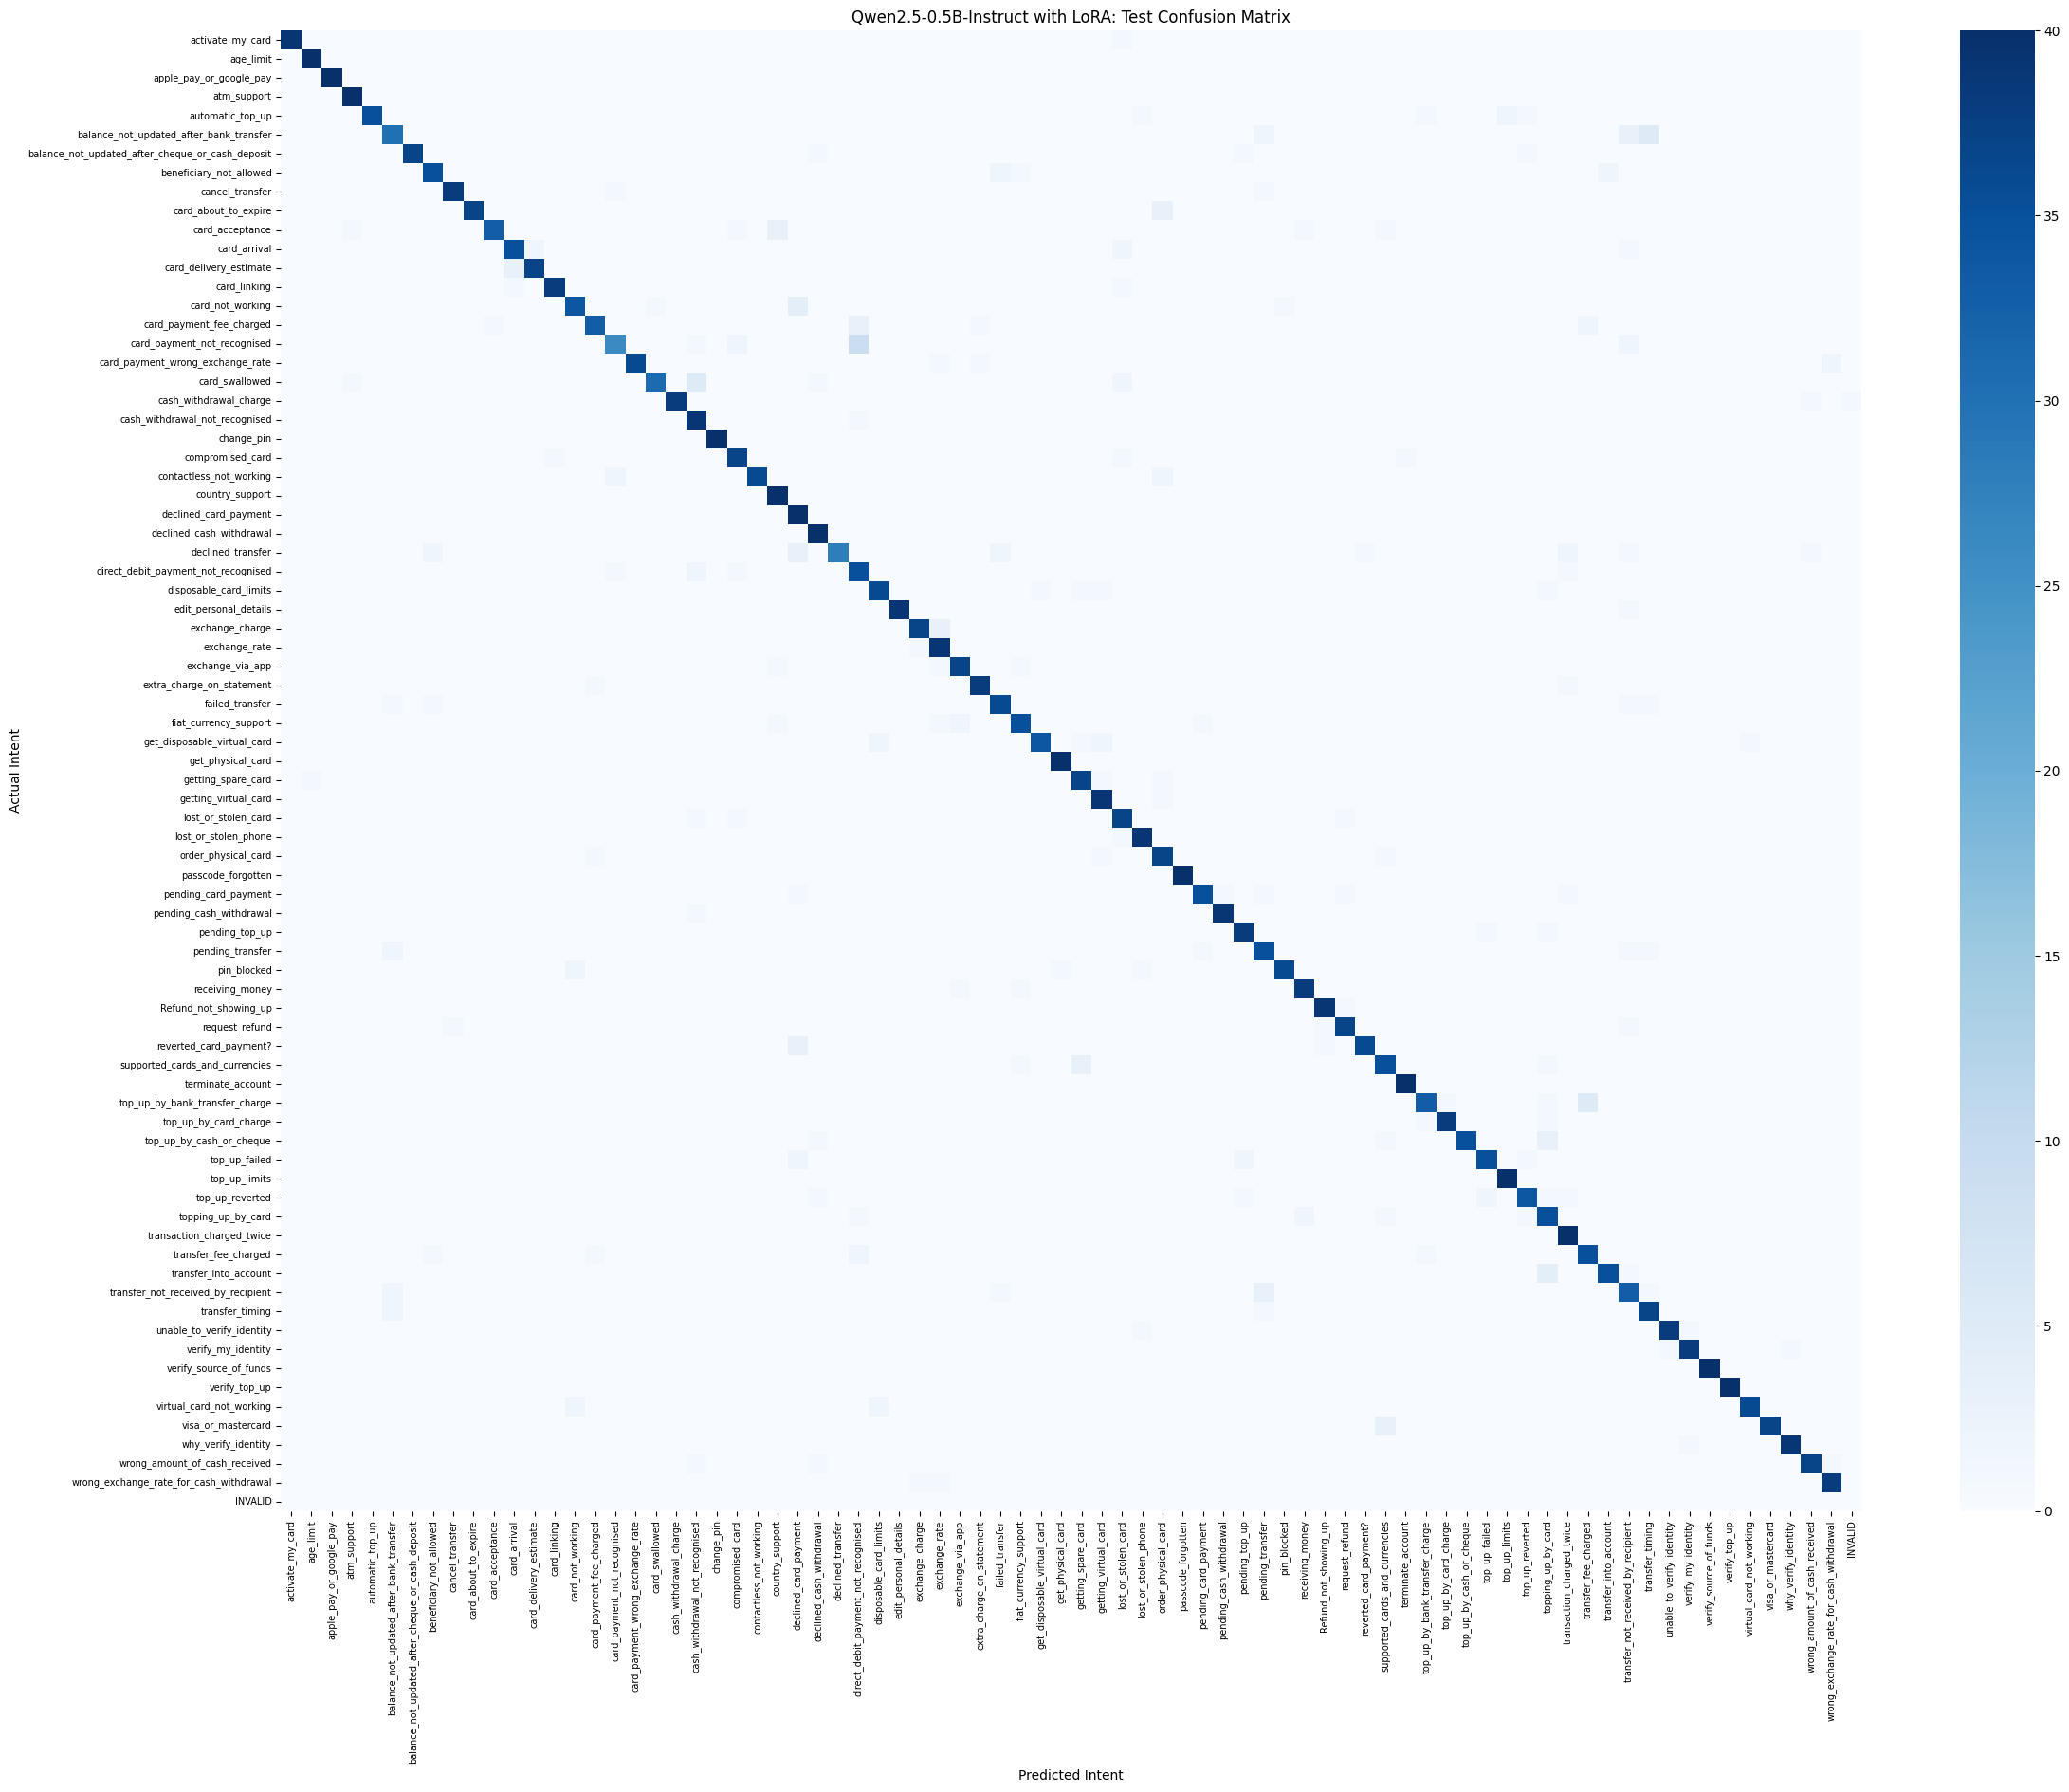

Fine-tuned model unloaded successfully.
All results saved to: /content/drive/MyDrive/Banking77_LoRA/results


In [59]:
cm_ft_pred = np.where(y_pred_ft == -1, NUM_CLASSES, y_pred_ft)
cm_ft = confusion_matrix(
    y_true,
    cm_ft_pred,
    labels=list(range(NUM_CLASSES + 1))
)

plt.figure(figsize=(24, 19))
sns.heatmap(
    cm_ft,
    cmap="Blues",
    xticklabels=class_names + ["INVALID"],
    yticklabels=class_names + ["INVALID"]
)
plt.title("Qwen2.5-0.5B-Instruct with LoRA: Test Confusion Matrix")
plt.xlabel("Predicted Intent")
plt.ylabel("Actual Intent")
plt.xticks(rotation=90, fontsize=7)
plt.yticks(rotation=0, fontsize=7)
plt.tight_layout()
plt.savefig(
    f"{BASE_OUTPUT_DIR}/lora_confusion_matrix.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()

del model
del base_model
gc.collect()
torch.cuda.empty_cache()

print("Fine-tuned model unloaded successfully.")
print("All results saved to:", BASE_OUTPUT_DIR)